# Deep Learning Project — Cats vs Dogs Image Classification

**Goal:** build a model that looks at a photo and decides whether it shows a **cat** or a **dog**
(binary image classification). We follow the same end-to-end workflow as a classical machine-learning
project — understand the data first, then select, tune, evaluate and decide how the model will be used.

| Part | Stage | What happens |
|---|---|---|
| A | 1 – 4 | Background: deep learning, image classification, CNNs, how images become numbers |
| B | 5 | Load the data (TensorFlow Datasets `cats_vs_dogs`) |
| B | 6 | **Exploratory data analysis** — data quality, univariate, bivariate, correlation |
| B | 7 | Data cleaning & leakage-safe train / validation / test split |
| B | 8 | Preprocessing & augmentation pipeline (`tf.data`) |
| C | 9 | Classical-ML baselines — how far do hand-made features get us? |
| C | 10 | **Model selection** — CNN from scratch vs deeper CNN vs transfer learning |
| C | 11 | **Hyperparameter tuning** |
| C | 12 | Final training + fine-tuning |
| D | 13 | **Model quality** — metrics, ROC / PR, calibration, error analysis, Grad-CAM |
| D | 14 | **Decision policy** — threshold and "ask a human" zone |
| E | 15 | **Improvements** — brightness augmentation for dark photos, "is this a pet photo?" gate |
| E | 16 | Pipeline summary & conclusions |

> **Runtime.** Written for Google Colab (*Runtime → Change runtime type → GPU* is strongly recommended)
> but also runs on a laptop CPU — the training budgets shrink automatically when no GPU is found.
> All figures are written to `results/figures/` and all numbers to `results/metrics.json`.

**Project notes (original)**
- ML-paper-based
- pl-projected based
- Question: will the machine learning material being sent? When?
- DataService-reuqest

# 1. What is deep learning?

**Deep learning** is the branch of machine learning that learns from data with *neural networks that have
many layers*. Each layer turns its input into a slightly more abstract representation; stacking many layers
lets the network go from raw pixels → edges → textures → parts (ears, snouts) → "this is a dog".

### Feature engineering: classical ML vs deep learning
In classical ML **we** design the features (colour histograms, image size, edge counts…) and the model only
learns how to combine them. In deep learning the network **learns the features itself** from raw data.
Section 9 vs Section 10 shows this in practice on this dataset: the best model on hand-made features reaches 65.2 % validation accuracy, the transfer-learning CNN 98.5 % before tuning and 98.37 % on the test set after the final training.

### The neuron and activation functions
A neuron computes a weighted sum of its inputs plus a bias, then applies a non-linear **activation function**:
$\;a = f(w_1x_1 + \dots + w_nx_n + b)$. Without the non-linearity, any stack of layers would collapse into one
linear model.

| Activation | Formula | Range | Typical use |
|---|---|---|---|
| **ReLU** | $\max(0, z)$ | $[0, \infty)$ | Hidden layers of CNNs — cheap, does not saturate for $z>0$ |
| **Tanh** | $\dfrac{e^z-e^{-z}}{e^z+e^{-z}}$ | $(-1, 1)$ | Zero-centred; RNNs; saturates for large $|z|$ |
| **Sigmoid** | $\dfrac{1}{1+e^{-z}}$ | $(0, 1)$ | **Output layer for binary classification** — reads as $P(\text{dog})$ |

### Neural network & training
1. **Forward pass** – the input flows through the layers to a prediction.
2. **Loss** – measures how wrong the prediction is. For two classes we use *binary cross-entropy*
   $\;L = -[y\log p + (1-y)\log(1-p)]$.
3. **Backpropagation** – the chain rule gives the gradient of the loss w.r.t. every weight.
4. **Optimizer** – updates the weights a small step against the gradient (SGD, **Adam**, RMSprop).

### Parameters vs hyperparameters
*Parameters* (weights, biases) are learned. *Hyperparameters* are chosen by us before training:
1. **Learning rate** – size of each update step. Too big → training diverges; too small → very slow.
2. **Batch size** – how many images are used for one gradient estimate (memory vs noise trade-off).
3. **Epochs** – how many full passes over the training set. Too many → overfitting (use early stopping).
4. Others: number/size of layers, dropout rate, data-augmentation strength, optimizer choice.

### Overfitting and regularisation
A model that memorises the training images but fails on new ones is *overfitting*. Remedies used in this
project: **data augmentation**, **dropout**, **batch normalisation**, **early stopping**, and
**transfer learning** (start from weights already trained on 1.2 M ImageNet images).

TensorFlow guide: https://www.tensorflow.org/guide

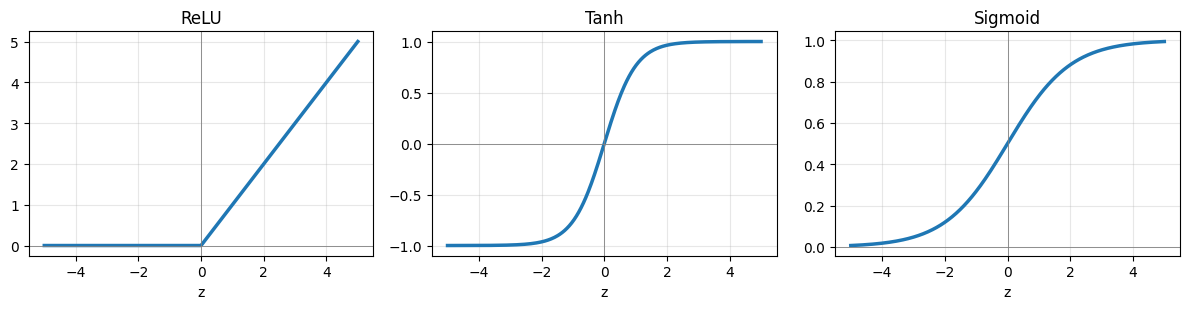

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# Visualise the three activation functions discussed above
z = np.linspace(-5, 5, 400)
acts = {"ReLU": np.maximum(0, z), "Tanh": np.tanh(z), "Sigmoid": 1 / (1 + np.exp(-z))}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (name, a) in zip(axes, acts.items()):
    ax.plot(z, a, lw=2.5)
    ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
    ax.set_title(name); ax.set_xlabel("z"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# 2. What is image classification?
Image classification assigns **one label to a whole image**. Here it is **binary classification**:
two classes, `cat = 0` and `dog = 1`. The network outputs one number $p = P(\text{dog} \mid \text{image})$;
we predict *dog* when $p \ge$ a threshold (0.5 by default — revisited in Section 14).

Related but different tasks: *object detection* (where is each animal → boxes) and
*segmentation* (which pixels belong to the animal).

# 3. Why a CNN?
A **Convolutional Neural Network** scans the image with **small filters** (e.g. 3×3 pixels). Each filter
is a tiny pattern detector (an edge, a colour blob, later an eye or fur texture) that slides over the whole
image and produces a *feature map*.

* **Weight sharing** – the same 3×3 filter is reused at every position, so a CNN needs far fewer parameters.
  A dense layer connecting a 160×160×3 image to 128 neurons needs 76 800 × 128 ≈ **9.8 M weights**;
  a 3×3 conv layer with 32 filters needs 3·3·3·32 + 32 = **896**.
* **Locality** – nearby pixels are related; filters look at local neighbourhoods.
* **Translation invariance** – a cat in the corner is detected by the same filter as a cat in the centre;
  **pooling** layers (max-pool 2×2) shrink the maps and add tolerance to small shifts.
* **Hierarchy** – early layers learn edges, deeper layers combine them into parts and objects.

Typical block: `Conv2D → (BatchNorm) → ReLU → MaxPooling`, repeated, then
`GlobalAveragePooling → Dropout → Dense(1, sigmoid)`.

# 4. Image processing
Resource: https://datacarpentry.github.io/image-processing/

Image processing is iterative and takes time — we look at the images, transform them, look again.

## 4.1 What is a pixel?
A **pixel** (*picture element*) is the smallest unit of a digital image: one sample of colour/brightness
at one position on a grid.

## 4.2 Images are arrays of numbers
A computer stores an image as a **NumPy array**. A grayscale image is a 2-D array (height × width)
where each entry is a brightness value, usually an 8-bit integer from **0 (black)** to **255 (white)**.

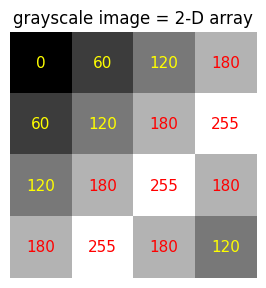

shape: (4, 4) | dtype: uint8 | min/max: 0 255


In [18]:
import numpy as np
import matplotlib.pyplot as plt

# A grayscale image is just a 2-D array: one brightness value (0 = black ... 255 = white) per pixel
gray = np.array([[  0,  60, 120, 180],
                 [ 60, 120, 180, 255],
                 [120, 180, 255, 180],
                 [180, 255, 180, 120]], dtype=np.uint8)

fig, ax = plt.subplots(figsize=(3.2, 3.2))
ax.imshow(gray, cmap="gray", vmin=0, vmax=255)
for (r, c), v in np.ndenumerate(gray):
    ax.text(c, r, v, ha="center", va="center", color="red" if v > 127 else "yellow", fontsize=11)
ax.set_title("grayscale image = 2-D array"); ax.axis("off")
plt.show()
print("shape:", gray.shape, "| dtype:", gray.dtype, "| min/max:", gray.min(), gray.max())

## 4.3 How does colour work?
Screens mix light **additively**: every colour is a combination of **R**ed, **G**reen and **B**lue light.
(255, 0, 0) is pure red, (255, 255, 0) is yellow, (255, 255, 255) is white and (0, 0, 0) is black.

## 4.4 Colour channels
A colour image therefore has **3 channels** (RGB) and is a 3-D array of shape **(height, width, 3)**.
Each channel on its own is a grayscale image showing how much of that primary colour each pixel contains.

## 4.5 A 3×3 RGB image as numbers
Below: a 3×3 image needs 3 × 3 × 3 = 27 numbers.

## 4.6 Shape conventions
TensorFlow uses **channels-last**: one image is `(H, W, C)` and a *batch* of images is `(N, H, W, C)`.
Our model input will be a batch of shape `(32, 160, 160, 3)`.

## 4.7 Why do we process images?
1. **Resizing** – photos come in many sizes (Section 6 shows 4 px to 500 px); a network needs a fixed input
   size, so we resize everything to 160 × 160.
2. **Colour channels** – make sure every image has exactly 3 channels (some photos are grayscale or RGBA).
3. **Rescaling and normalising** – convert 0–255 integers to small floats (0–1 or −1–1) so gradients are
   well-behaved; pretrained models expect the exact scaling they were trained with.
4. **Labels** – map each image to an integer class (`cat = 0`, `dog = 1`).
5. **Training, validation and testing sets** – train on one part, tune on a second, and report the final
   score on a third part the model has never influenced.
6. **Augmentation** – random flips / rotations / zooms create new training variants and reduce overfitting.

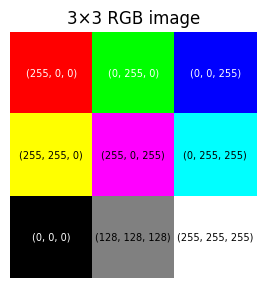

shape: (3, 3, 3) -> (height, width, channels)


In [19]:
# 4.5 – a 3x3 RGB image: every pixel holds (R, G, B)
rgb = np.array([[[255,   0,   0], [  0, 255,   0], [  0,   0, 255]],
                [[255, 255,   0], [255,   0, 255], [  0, 255, 255]],
                [[  0,   0,   0], [128, 128, 128], [255, 255, 255]]], dtype=np.uint8)
fig, ax = plt.subplots(figsize=(3.2, 3.2))
ax.imshow(rgb); ax.set_title("3×3 RGB image"); ax.axis("off")
for (r, c), _ in np.ndenumerate(rgb[..., 0]):
    ax.text(c, r, str(tuple(int(v) for v in rgb[r, c])), ha="center", va="center", fontsize=7,
            color="white" if rgb[r, c].mean() < 128 else "black")
plt.show()
print("shape:", rgb.shape, "-> (height, width, channels)")

[[[116  85  57]
  [128 109  94]
  [214  44  62]
  [219 157  21]]

 [[ 93 152 140]
  [246 198 102]
  [ 70  33 101]
  [  7   1 110]]

 [[225 124 229]
  [154 194 176]
  [227  63  49]
  [144 178  54]]

 [[123 180  93]
  [120   5  49]
  [166 234 142]
  [ 71  85  70]]]


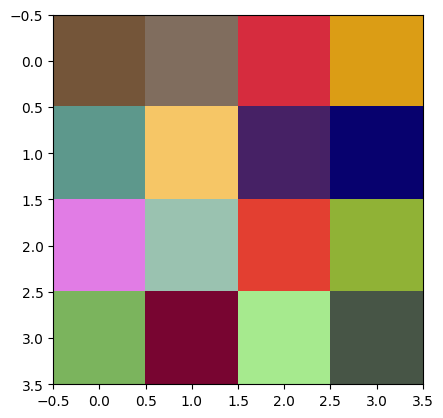

In [20]:
# set the random seed so we all get the same matrix
pseudorandomizer = np.random.RandomState(2021)
# create a 4 × 4 checkerboard of random colours
checkerboard = pseudorandomizer.randint(0, 255, size=(4, 4, 3))
# restore the default map as you show the image
fig, ax = plt.subplots()
ax.imshow(checkerboard)
# display the arrays
print(checkerboard)

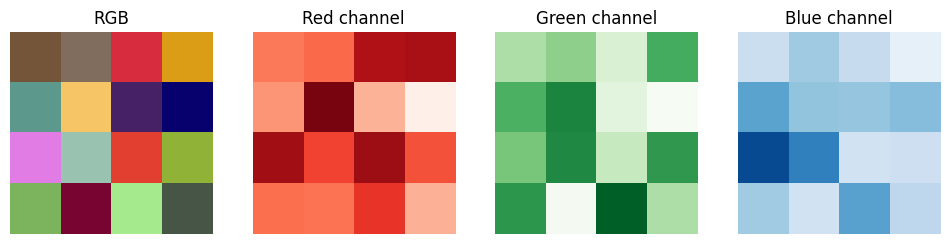

In [21]:
# Each channel of the checkerboard shown on its own (bright = a lot of that colour)
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(checkerboard); axes[0].set_title("RGB")
for i, (name, cmap) in enumerate([("Red", "Reds"), ("Green", "Greens"), ("Blue", "Blues")], start=1):
    axes[i].imshow(checkerboard[..., i - 1], cmap=cmap, vmin=0, vmax=255)
    axes[i].set_title(f"{name} channel")
for ax in axes: ax.axis("off")
plt.show()

## From pixels to a CNN prediction
`JPEG file → decode to array (H, W, 3) → resize to 160×160 → rescale → conv blocks → feature maps →
global pooling → dense layer → sigmoid → P(dog)`

# 5. Load the Cats vs Dogs dataset
* TensorFlow Datasets catalogue: https://www.tensorflow.org/datasets/catalog/cats_vs_dogs
* Original source (Microsoft Research **Asirra** CAPTCHA, photos from Petfinder.com):
  https://www.microsoft.com/en-us/download/details.aspx?id=54765
* Same images on Kaggle: https://www.kaggle.com/competitions/dogs-vs-cats
  and https://www.kaggle.com/datasets/shaunthesheep/microsoft-catsvsdogs-dataset

The raw archive holds 25 000 JPEGs (12 500 per class). TFDS drops **1 738 files that cannot be decoded**,
leaving **23 262** usable images that come as a single `train` split — we create our own
validation/test split in Section 7.

Task: image classification (binary).

In [15]:
import sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:  # Colab only – locally the packages are installed once in the environment
    !pip install -q tensorflow-datasets protobuf --upgrade

In [16]:
import sys
import os

# Install missing dependency required by tensorflow-datasets
try:
    import importlib_resources
except ImportError:
    os.system('pip install -q importlib_resources')

import tensorflow_datasets as tfds
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

(raw_ds, ds_info) = tfds.load(
    'cats_vs_dogs',
    split='train',
    with_info=True,
    as_supervised=True,
    shuffle_files=True,
    download=True
    )
class_names = ["cat", "dog"]
print(ds_info)

tfds.core.DatasetInfo(
    name='cats_vs_dogs',
    full_name='cats_vs_dogs/4.0.1',
    description="""
    A large set of images of cats and dogs. There are 1738 corrupted images that are dropped.
    """,
    homepage='https://www.microsoft.com/en-us/download/details.aspx?id=54765',
    data_dir='/root/tensorflow_datasets/cats_vs_dogs/4.0.1',
    file_format=tfrecord,
    download_size=786.67 MiB,
    dataset_size=1.04 GiB,
    features=FeaturesDict({
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'image/filename': Text(shape=(), dtype=string),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=2),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'train': <SplitInfo num_examples=23262, num_shards=16>,
    },
    citation="""@Inproceedings (Conference){asirra-a-captcha-that-exploits-interest-aligned-manual-image-categorization,
    author = {Elson, Jeremy and Douceur, Jo

### Project configuration
All global settings live in one place. Training budgets depend on whether a GPU is available;
`EarlyStopping` usually ends training before the budget is used up anyway.

In [22]:
import os, re, gc, json, time, warnings
import pandas as pd
import seaborn as sns
from scipy import stats

SEED = 42
keras.utils.set_random_seed(SEED)          # python, numpy and tensorflow seeds
IMG_SIZE = 160                             # MobileNetV2 has ImageNet weights for 96/128/160/192/224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
ON_GPU = len(tf.config.list_physical_devices("GPU")) > 0
SMOKE_TEST = os.environ.get("CVD_SMOKE_TEST") == "1"   # tiny end-to-end run for debugging the notebook

BUDGET = dict(select_epochs=12 if ON_GPU else 5,    # model-selection runs (same budget for every candidate)
              tune_epochs=20,                       # hyperparameter trials on cached features (fast)
              head_epochs=10 if ON_GPU else 3,      # final model, frozen base
              finetune_epochs=10 if ON_GPU else 2)  # final model, top of base unfrozen
SELECT_SUBSET = None if ON_GPU else 4000      # CPU: screen candidates on a fixed subset of training images
if SMOKE_TEST:
    BUDGET = {k: 1 for k in BUDGET}

RESULTS_DIR = "results"
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
CACHE_DIR = os.path.join(RESULTS_DIR, "cache")       # each finished training stage is saved here
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(CACHE_DIR, exist_ok=True)
REUSE_SAVED = True     # True: load finished stages from results/cache instead of retraining; False: retrain everything
RESULTS = {"config": dict(seed=SEED, img_size=IMG_SIZE, batch_size=BATCH_SIZE, on_gpu=ON_GPU, select_subset=SELECT_SUBSET,
                          tensorflow=tf.__version__, budget=BUDGET)}

CLASS_COLORS = {"cat": "#E07A5F", "dog": "#3D5A80"}
sns.set_theme(style="whitegrid", context="notebook")
warnings.filterwarnings("ignore", category=UserWarning, module="keras")   # tf.data / epoch-iterator notices

def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=110, bbox_inches="tight")

def saved(name):
    # path of a saved stage result if it exists and reuse is on, else None
    path = os.path.join(CACHE_DIR, name)
    return path if REUSE_SAVED and os.path.exists(path) else None

def progress(msg):
    # one-line progress log (results/cache/progress.log), handy for long CPU runs
    with open(os.path.join(CACHE_DIR, "progress.log"), "a") as fh:
        fh.write(f"{time.strftime('%H:%M:%S')}  {msg}\n")

class ProgressLog(keras.callbacks.Callback):
    def __init__(self, tag):
        super().__init__(); self.tag = tag
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        progress(f"{self.tag} epoch {epoch + 1}: val_accuracy={logs.get('val_accuracy', float('nan')):.4f} val_loss={logs.get('val_loss', float('nan')):.4f}")

print("TensorFlow", tf.__version__, "| GPU:", ON_GPU, "| smoke test:", SMOKE_TEST)
print("budget:", BUDGET)

TensorFlow 2.21.0 | GPU: True | smoke test: False
budget: {'select_epochs': 12, 'tune_epochs': 20, 'head_epochs': 10, 'finetune_epochs': 10}


# 6. Exploratory data analysis (EDA)

For tabular data EDA looks at columns. For images we first **turn every image into a row of
image-level descriptors** and then apply the familiar EDA toolkit to that table:

| Feature | Meaning |
|---|---|
| `height`, `width`, `aspect`, `megapixels` | geometry of the original photo |
| `mean_r`, `mean_g`, `mean_b` | average intensity of each colour channel |
| `brightness` | mean grayscale intensity |
| `contrast` | standard deviation of grayscale intensity |
| `colorfulness` | mean absolute difference between channels (≈ 0 for a grayscale photo) |
| `sharpness` | variance of the Laplacian (low = blurry) |
| `hash` | 16×16 perceptual *average hash* — identical for (near-)duplicate images |

The order of work mirrors a classical ML project: **6.1** first look → **6.2** build the feature table →
**6.3** data quality → **6.4** univariate → **6.5** bivariate → **6.6** correlation → **6.7** summary.

## 6.1 First look at the images

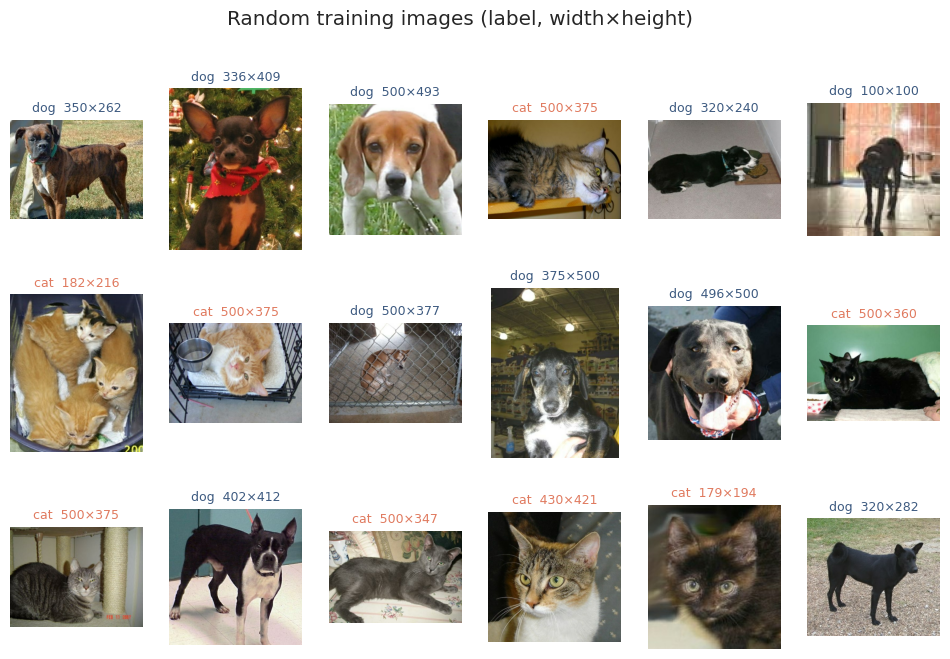

In [23]:
plt.figure(figsize=(12, 7.5))
for i, (image, label) in enumerate(raw_ds.take(18)):
    ax = plt.subplot(3, 6, i + 1)
    plt.imshow(image.numpy())
    plt.title(f"{class_names[int(label)]}  {image.shape[1]}×{image.shape[0]}", fontsize=9,
              color=CLASS_COLORS[class_names[int(label)]])
    plt.axis("off")
plt.suptitle("Random training images (label, width×height)")
save_fig("samples"); plt.show()

**What we see:** real-world photos — different sizes and aspect ratios, indoor/outdoor, several animals
in one picture, people holding pets, cages, text overlays. The animal is not always centred or large.
This variety is exactly why simple rules will not work.

## 6.2 Build the image-feature table
One pass over all 23 262 images (decoded at full resolution) computes the descriptors above.
We also keep a 32×32 grayscale thumbnail and an 8-bin colour histogram of every image for the classical
baselines in Section 9, and accumulate the mean 64×64 image per class.

In [24]:
eda_ds = tfds.load("cats_vs_dogs", split="train", shuffle_files=False)   # dict examples incl. filename
if SMOKE_TEST:
    eda_ds = eda_ds.take(1500)

LAPLACIAN = tf.constant([[0., 1., 0.], [1., -4., 1.], [0., 1., 0.]])[:, :, None, None]

def describe(example):
    img = example["image"]
    shape = tf.shape(img)
    x = tf.cast(img, tf.float32)
    gray = tf.image.rgb_to_grayscale(x)
    small = tf.image.resize(gray, (128, 128), method="area")
    lap = tf.nn.conv2d(small[None], LAPLACIAN, strides=1, padding="VALID")
    h16 = tf.image.resize(gray, (16, 16), method="area")[..., 0]
    return {
        "filename": example["image/filename"], "label": example["label"],
        "height": shape[0], "width": shape[1],
        "rgb_mean": tf.reduce_mean(x, axis=[0, 1]),
        "brightness": tf.reduce_mean(gray), "contrast": tf.math.reduce_std(gray),
        "colorfulness": tf.reduce_mean(tf.abs(x[..., 0] - x[..., 1]) + tf.abs(x[..., 1] - x[..., 2])) / 2,
        "sharpness": tf.math.reduce_variance(lap),
        "hash_bits": h16 > tf.reduce_mean(h16),
        "thumb32": tf.cast(tf.image.resize(gray, (32, 32), method="area")[..., 0], tf.uint8),
        "thumb64": tf.image.resize(x, (64, 64), method="area"),
        "hist": tf.stack([tf.histogram_fixed_width(x[..., c], [0., 256.], nbins=8) for c in range(3)]),
    }

t0 = time.perf_counter()
rows, thumbs32, hists = [], [], []
mean_img_sum = {0: np.zeros((64, 64, 3)), 1: np.zeros((64, 64, 3))}
for d in eda_ds.map(describe, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE).as_numpy_iterator():
    lbl = int(d["label"])
    rows.append(dict(filename=d["filename"].decode(), label=lbl, height=int(d["height"]), width=int(d["width"]),
                     mean_r=d["rgb_mean"][0], mean_g=d["rgb_mean"][1], mean_b=d["rgb_mean"][2],
                     brightness=float(d["brightness"]), contrast=float(d["contrast"]),
                     colorfulness=float(d["colorfulness"]), sharpness=float(d["sharpness"]),
                     hash=np.packbits(d["hash_bits"].ravel()).tobytes().hex()))
    thumbs32.append(d["thumb32"])
    hists.append(d["hist"].ravel() / (int(d["height"]) * int(d["width"])))
    mean_img_sum[lbl] += d["thumb64"]

df = pd.DataFrame(rows)
df["class"] = df["label"].map({0: "cat", 1: "dog"})
df["aspect"] = df["width"] / df["height"]
df["megapixels"] = df["width"] * df["height"] / 1e6
thumbs32 = np.stack(thumbs32)
hists = np.stack(hists).astype(np.float32)
print(f"described {len(df):,} images in {time.perf_counter() - t0:.0f}s")
df.head()

described 23,262 images in 164s


,filename,label,height,width,mean_r,mean_g,mean_b,brightness,contrast,colorfulness,sharpness,hash,class,aspect,megapixels
0,PetImages/Dog/10396.jpg,1,262,350,116.757339,108.022072,84.091537,107.894165,63.411152,19.293598,2097.375244,07ff33ffa3ff83ffa30b20036003e003f00378037823f8...,dog,1.335878,0.091700
1,PetImages/Dog/4077.jpg,1,409,336,94.936394,66.788666,35.243298,71.599174,37.933819,30.706812,1397.479858,f8b9f081d01dda5d8807301ef4100d1ce40cac073c03f1...,dog,0.821516,0.137424
2,PetImages/Dog/10497.jpg,1,493,500,144.410294,137.234619,109.081528,136.156967,50.489056,25.154842,795.391418,fff8fff8e7e88640800001000380c3c16be34e637e7672...,dog,1.014199,0.246500
3,PetImages/Cat/2763.jpg,0,375,500,102.384232,88.544991,61.016853,89.534645,46.171116,22.378704,792.364807,0fff0fff07f907fd013d001c0066007c017dc27fc3fa06...,cat,1.333333,0.187500
4,PetImages/Dog/11257.jpg,1,240,320,115.622894,111.516975,105.935402,112.096786,55.316990,6.145879,552.998413,e03fffffffffffffffcfe0018009000900100010027f8f...,dog,1.333333,0.076800


In [25]:
FEATURES = ["height", "width", "aspect", "megapixels", "mean_r", "mean_g", "mean_b",
            "brightness", "contrast", "colorfulness", "sharpness"]
df[FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
height,23262.0,364.85,96.24,4.00,316.00,375.00,428.00,500.00
width,23262.0,410.22,107.96,4.00,336.00,467.00,500.00,500.00
aspect,23262.0,1.16,0.29,0.31,0.93,1.30,1.33,3.36
megapixels,23262.0,0.15,0.06,0.00,0.12,0.18,0.19,0.25
mean_r,23262.0,122.36,29.69,20.39,102.70,122.21,141.11,254.00
mean_g,23262.0,115.98,28.32,15.52,97.60,116.01,133.60,254.00
mean_b,23262.0,103.93,29.55,2.66,84.10,102.86,122.49,254.00
brightness,23262.0,116.50,27.70,20.29,98.41,116.27,133.54,253.97
contrast,23262.0,56.94,13.56,0.00,47.55,56.54,65.87,115.19
colorfulness,23262.0,16.27,9.74,0.00,9.41,13.95,20.62,125.32


## 6.3 Data quality
Checks a reviewer would ask for in any ML project:

1. **Completeness** — corrupted files, missing values, label validity.
2. **Label consistency** — does the label agree with the folder the file came from (`PetImages/Cat/...`)?
3. **Unusual images** — tiny images, extreme aspect ratios, grayscale photos, near-blank or blurry images.
4. **Duplicates** — the same photo stored twice; worst case with *different* labels (label noise), and
   duplicates that would end up in both train and test (**data leakage** → optimistic test score).

In [26]:
n_raw, n_ok = 25000, ds_info.splits["train"].num_examples
print(f"raw archive: {n_raw:,} files | decodable (kept by TFDS): {n_ok:,} | corrupted & dropped: {n_raw - n_ok:,}")
print("missing values per column:", int(df.isna().sum().sum()))
print("label values:", sorted(df["label"].unique()))

df["folder"] = df["filename"].str.extract(r"(Cat|Dog)", flags=re.IGNORECASE)[0].str.lower()
mismatch = (df["folder"] != df["class"]).sum()
print(f"label vs folder mismatches: {mismatch}")

# --- quality flags --------------------------------------------------------
hash_size = df.groupby("hash")["hash"].transform("size")
hash_nlabels = df.groupby("hash")["label"].transform("nunique")
sharp_cut = df["sharpness"].quantile(0.01)
flags = pd.DataFrame({
    "tiny (min side < 100 px)": df[["height", "width"]].min(axis=1) < 100,
    "extreme aspect (<0.5 or >2)": (df["aspect"] < 0.5) | (df["aspect"] > 2),
    "grayscale photo": df["colorfulness"] < 2,
    "near-blank (contrast < 10)": df["contrast"] < 10,
    "blurry (lowest 1 % sharpness)": df["sharpness"] < sharp_cut,
    "duplicate (same hash)": hash_size > 1,
    "duplicate with conflicting labels": hash_nlabels > 1,
})
df["duplicate_copy"] = df.duplicated("hash", keep="first") & (hash_nlabels == 1)
df["conflict_dup"] = hash_nlabels > 1
df["near_blank"] = flags["near-blank (contrast < 10)"]

action = {"tiny (min side < 100 px)": "keep – real input, resized anyway",
          "extreme aspect (<0.5 or >2)": "keep – resize stretches; augmentation helps",
          "grayscale photo": "keep – valid photo, converted to 3 channels",
          "near-blank (contrast < 10)": "remove – no animal visible",
          "blurry (lowest 1 % sharpness)": "keep – realistic",
          "duplicate (same hash)": "remove extra copies (keep one)",
          "duplicate with conflicting labels": "remove all copies (label noise)"}
quality = pd.DataFrame({"count": flags.sum(), "percent": (flags.mean() * 100).round(2)})
quality["action"] = quality.index.map(action)
RESULTS["quality"] = {"n_raw": n_raw, "n_decodable": int(n_ok), "corrupted": int(n_raw - n_ok),
                      "missing": int(df.isna().sum().sum()), "label_folder_mismatch": int(mismatch),
                      "flags": {k: int(v) for k, v in flags.sum().items()},
                      "duplicate_groups": int((df.groupby("hash").size() > 1).sum())}
quality

raw archive: 25,000 files | decodable (kept by TFDS): 23,262 | corrupted & dropped: 1,738
missing values per column: 0
label values: [np.int64(0), np.int64(1)]
label vs folder mismatches: 0


,count,percent,action
tiny (min side < 100 px),154,0.66,"keep – real input, resized anyway"
extreme aspect (<0.5 or >2),191,0.82,keep – resize stretches; augmentation helps
grayscale photo,34,0.15,"keep – valid photo, converted to 3 channels"
near-blank (contrast < 10),1,0.00,remove – no animal visible
blurry (lowest 1 % sharpness),233,1.00,keep – realistic
duplicate (same hash),52,0.22,remove extra copies (keep one)
duplicate with conflicting labels,2,0.01,remove all copies (label noise)


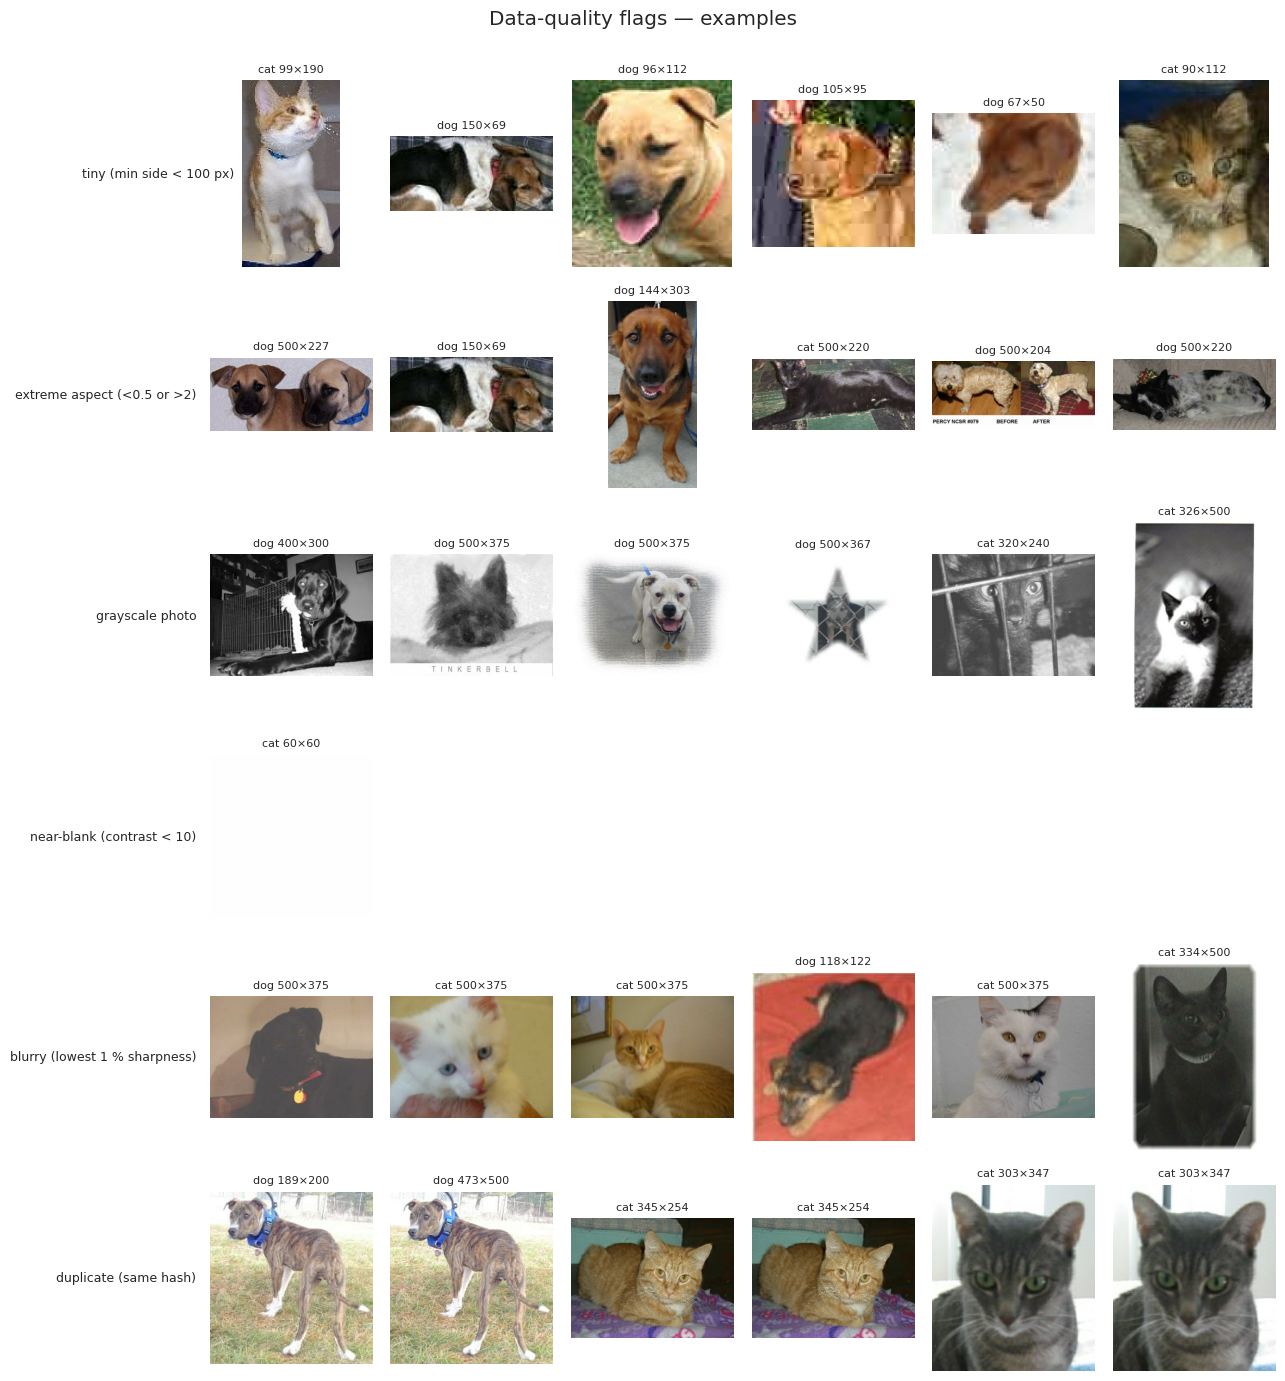

In [27]:
# Gallery: a few examples for each quality flag
show = [f for f in ["tiny (min side < 100 px)", "extreme aspect (<0.5 or >2)", "grayscale photo",
                    "near-blank (contrast < 10)", "blurry (lowest 1 % sharpness)", "duplicate (same hash)"]
        if flags[f].any()]                                   # skip flags with no examples
idx_by_flag = {f: df.index[flags[f]][:6].tolist() for f in show}
if flags["duplicate (same hash)"].any():   # show duplicate pairs side by side
    dup_hashes = df.loc[flags["duplicate (same hash)"], "hash"].unique()[:3]
    idx_by_flag["duplicate (same hash)"] = [i for h in dup_hashes for i in df.index[df["hash"] == h][:2]][:6]
wanted = sorted({i for v in idx_by_flag.values() for i in v})
lookup = {}
for i, ex in enumerate(eda_ds):
    if i in wanted:
        lookup[i] = ex["image"].numpy()
    if i > max(wanted, default=-1):
        break

fig, axes = plt.subplots(len(show), 6, figsize=(13, 2.3 * len(show)))
for r, f in enumerate(show):
    for c in range(6):
        ax = axes[r, c]; ax.axis("off")
        if c < len(idx_by_flag[f]):
            i = idx_by_flag[f][c]
            ax.imshow(lookup[i], cmap="gray")
            ax.set_title(f"{df.at[i, 'class']} {df.at[i, 'width']}×{df.at[i, 'height']}", fontsize=8)
    axes[r, 0].text(-0.08, 0.5, f, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
plt.suptitle("Data-quality flags — examples", y=1.0)
plt.tight_layout(); save_fig("quality_flags"); plt.show()

### Observations — data quality
* **Completeness:** 1,738 of 25,000 files were not valid JPEGs and were dropped by TFDS; the 23,262 remaining images have **0 missing values** and only valid labels.
* **Label consistency:** 0 labels disagree with the source folder name.
* **Unusual but valid images:** 154 tiny images, 191 extreme aspect ratios, 34 grayscale photos and 233 very blurry ones. They are real-world inputs, so they **stay** in the data.
* **Near-blank:** 1 image(s) with almost no contrast (no animal visible) → **removed**.
* **Duplicates:** the perceptual hash finds **26 groups** of duplicate photos (52 images), typically the same picture uploaded twice at different resolutions; 2 images sit in groups with conflicting labels. Extra copies are removed, and the split in Section 7 is grouped by hash so no duplicate can leak from training into test.

## 6.4 Univariate analysis
One variable at a time: the target (class balance) and the distribution of every image descriptor.

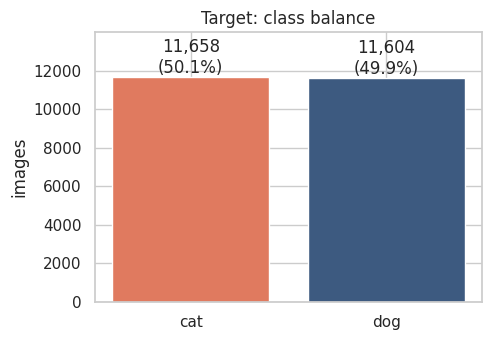

In [28]:
counts = df["class"].value_counts().reindex(class_names)
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(counts.index, counts.values, color=[CLASS_COLORS[c] for c in counts.index])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.2); ax.set_ylabel("images"); ax.set_title("Target: class balance")
save_fig("class_balance"); plt.show()
RESULTS["class_counts"] = {k: int(v) for k, v in counts.items()}

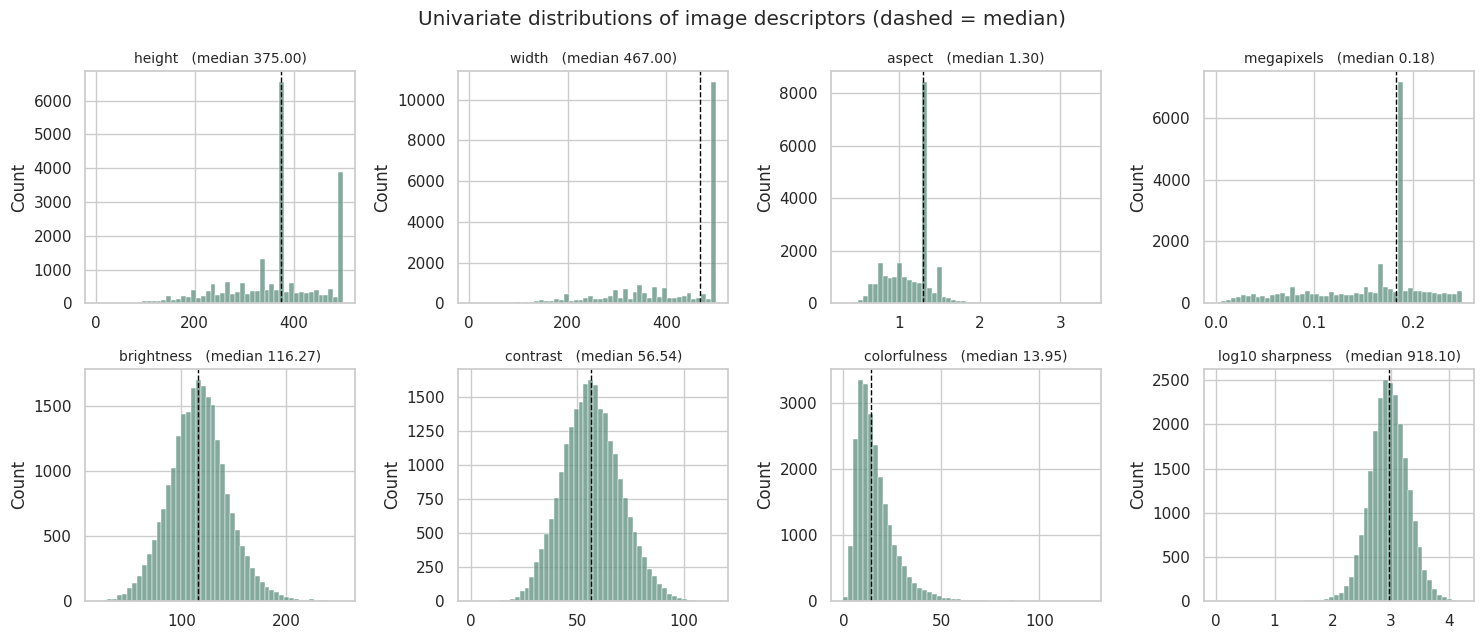

,height,width,aspect,megapixels,mean_r,mean_g,mean_b,brightness,contrast,colorfulness,sharpness
skewness,-0.51,-0.96,-0.01,-0.81,0.14,0.150000,0.31,0.19,0.17,1.7,3.3
mode/most common,375.00,500.00,1.30,0.20,131.00,116.699997,110.50,109.90,59.00,9.6,590.3


In [29]:
uni = ["height", "width", "aspect", "megapixels", "brightness", "contrast", "colorfulness", "sharpness"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, col in zip(axes.ravel(), uni):
    data = np.log10(df[col] + 1) if col == "sharpness" else df[col]
    sns.histplot(data, bins=50, ax=ax, color="#5B8E7D")
    ax.axvline(data.median(), color="black", ls="--", lw=1)
    ax.set_title(("log10 " if col == "sharpness" else "") + col + f"   (median {df[col].median():.2f})", fontsize=10)
    ax.set_xlabel("")
plt.suptitle("Univariate distributions of image descriptors (dashed = median)")
plt.tight_layout(); save_fig("univariate"); plt.show()

skew = df[FEATURES].skew().round(2).rename("skewness").to_frame()
skew["mode/most common"] = [df[c].round(1).mode()[0] for c in FEATURES]
skew.T

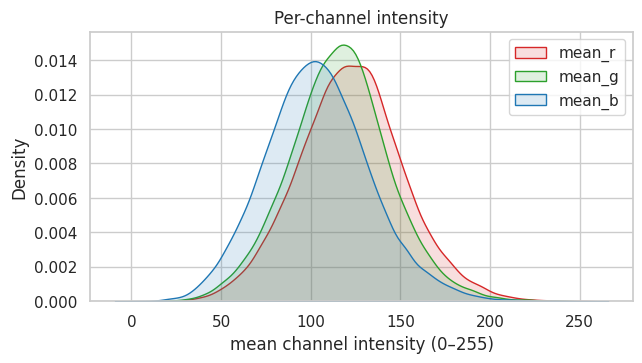

most common sizes (W×H):
500×375    5867
375×500     488
500×333     427
320×240     293
500×374     189
500×332     183
350×262     174
500×500     133


In [30]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for ch, colr in zip(["mean_r", "mean_g", "mean_b"], ["#d62728", "#2ca02c", "#1f77b4"]):
    sns.kdeplot(df[ch], ax=ax, color=colr, fill=True, alpha=0.15, label=ch)
ax.set_xlabel("mean channel intensity (0–255)"); ax.legend(); ax.set_title("Per-channel intensity")
save_fig("channels"); plt.show()

# summary of the most common image sizes
top_sizes = (df["width"].astype(str) + "×" + df["height"].astype(str)).value_counts().head(8)
print("most common sizes (W×H):"); print(top_sizes.to_string())

### Observations — univariate
* **Target:** 11,658 cats vs 11,604 dogs — practically balanced, so accuracy is a fair headline metric and no re-weighting is needed.
* **Geometry:** Petfinder capped the longer side at 500 px, so widths/heights pile up at 500 and the most common size is **500×375** (25% of images). Aspect ratio peaks at 4:3 (1.33). Sizes still range from a few dozen pixels to 500 → every image must be **resized** to a fixed input.
* **Intensity:** brightness and contrast are roughly bell-shaped; colourfulness is right-skewed with a small spike at 0 (grayscale photos); sharpness spans orders of magnitude (log-normal), so it is analysed on a log scale.

## 6.5 Bivariate analysis
Two variables at a time — mainly **each descriptor vs the target**. If any descriptor differed strongly
between cats and dogs, a simple model could use it. We use box plots, density overlays, a size scatter,
the average image per class, and a **Mann–Whitney U test** with an effect size for every feature.

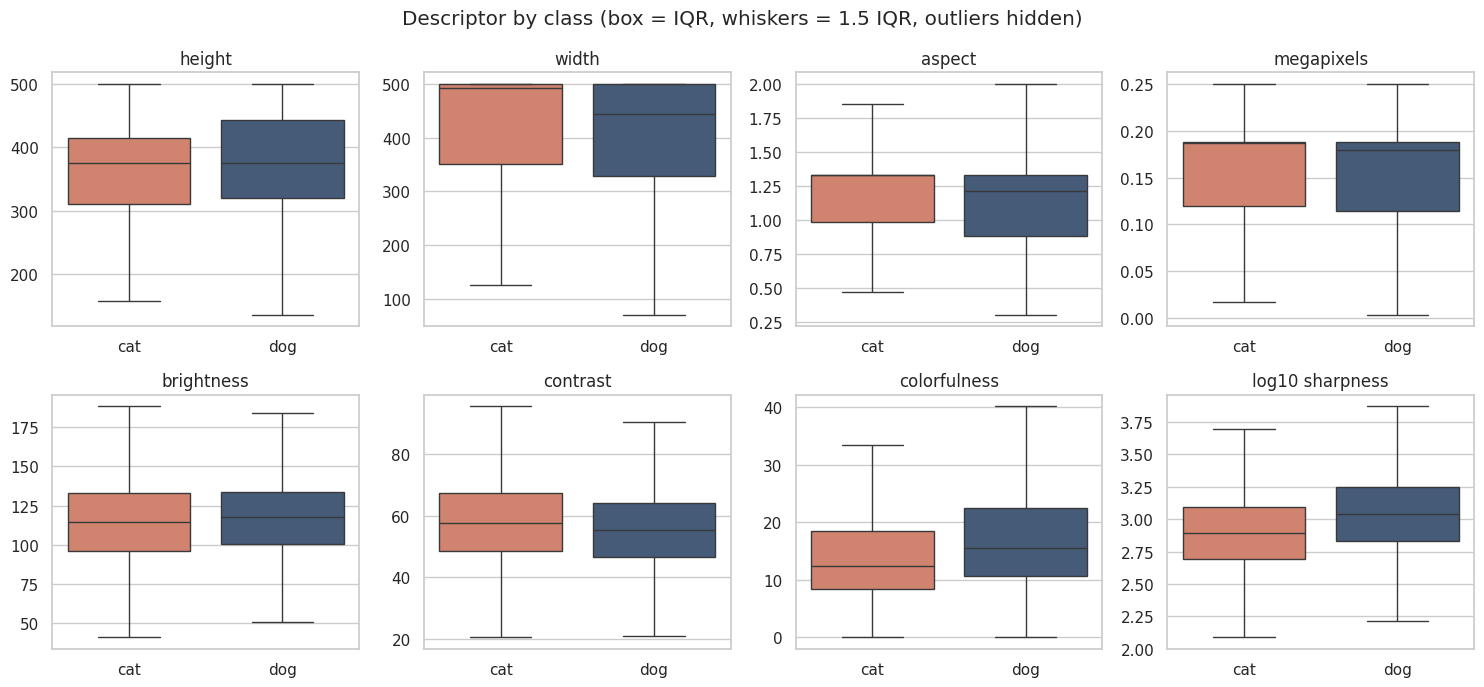

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.ravel(), uni):
    plot_df = df.assign(value=np.log10(df[col] + 1) if col == "sharpness" else df[col])
    sns.boxplot(data=plot_df, x="class", y="value", hue="class", palette=CLASS_COLORS, ax=ax,
                showfliers=False, legend=False, order=class_names)
    ax.set_title(("log10 " if col == "sharpness" else "") + col); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("Descriptor by class (box = IQR, whiskers = 1.5 IQR, outliers hidden)")
plt.tight_layout(); save_fig("bivariate_box"); plt.show()

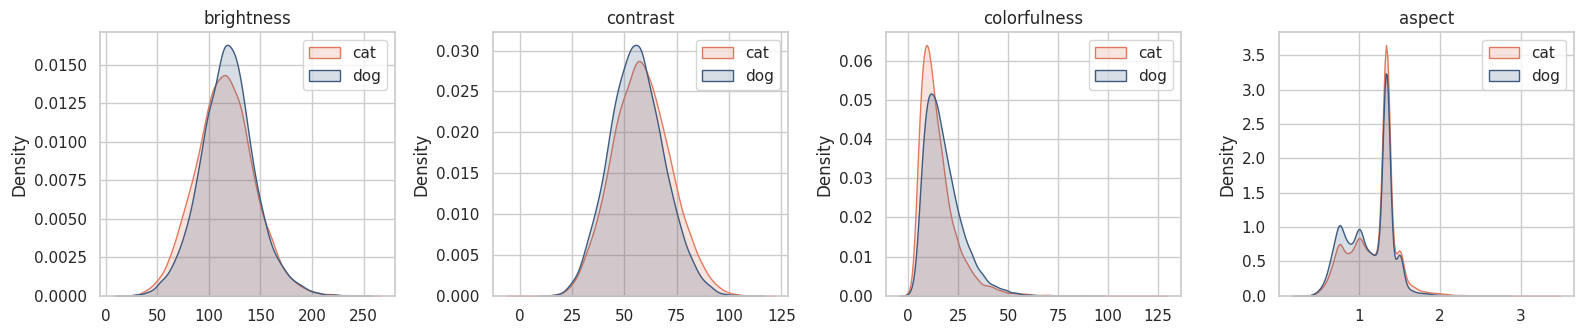

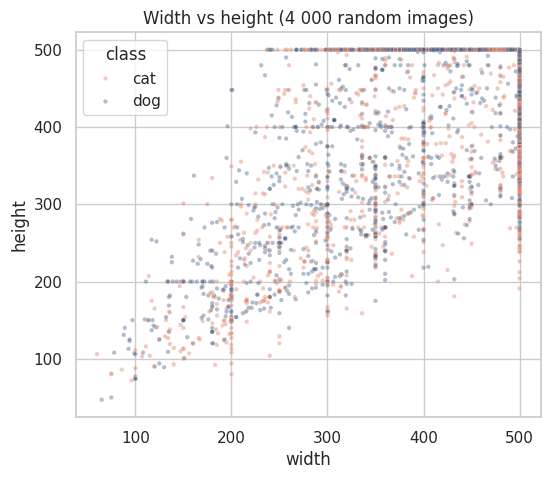

In [32]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["brightness", "contrast", "colorfulness", "aspect"]):
    for c in class_names:
        sns.kdeplot(df.loc[df["class"] == c, col], ax=ax, label=c, color=CLASS_COLORS[c], fill=True, alpha=0.2)
    ax.set_title(col); ax.set_xlabel(""); ax.legend()
plt.tight_layout(); save_fig("bivariate_kde"); plt.show()

sample = df.sample(min(4000, len(df)), random_state=SEED)
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(data=sample, x="width", y="height", hue="class", palette=CLASS_COLORS, s=10, alpha=0.4, ax=ax)
ax.set_title("Width vs height (4 000 random images)")
save_fig("size_scatter"); plt.show()

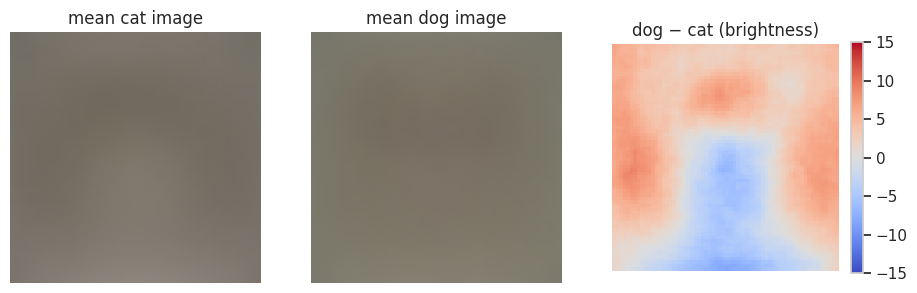

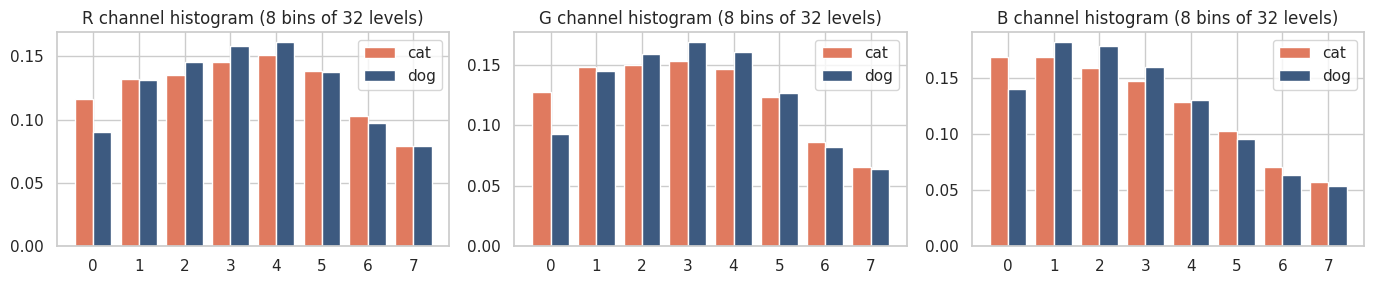

In [33]:
# Average image of each class and their difference
counts_lbl = df["label"].value_counts()
mean_cat = mean_img_sum[0] / counts_lbl[0]; mean_dog = mean_img_sum[1] / counts_lbl[1]
diff = mean_dog.mean(-1) - mean_cat.mean(-1)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
axes[0].imshow(mean_cat.astype(np.uint8)); axes[0].set_title("mean cat image")
axes[1].imshow(mean_dog.astype(np.uint8)); axes[1].set_title("mean dog image")
im = axes[2].imshow(diff, cmap="coolwarm", vmin=-15, vmax=15); axes[2].set_title("dog − cat (brightness)")
plt.colorbar(im, ax=axes[2], fraction=0.046)
for ax in axes: ax.axis("off")
save_fig("mean_images"); plt.show()

# Mean colour histogram per class
hist_cols = [f"{ch}{b}" for ch in "RGB" for b in range(8)]
hist_df = pd.DataFrame(hists, columns=hist_cols).assign(cls=df["class"].values)
mean_hist = hist_df.groupby("cls")[hist_cols].mean()
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
for ax, ch in zip(axes, "RGB"):
    w = 0.4; xs = np.arange(8)
    for k, c in enumerate(class_names):
        ax.bar(xs + (k - 0.5) * w, mean_hist.loc[c, [f"{ch}{b}" for b in range(8)]], w, color=CLASS_COLORS[c], label=c)
    ax.set_title(f"{ch} channel histogram (8 bins of 32 levels)"); ax.set_xticks(xs); ax.legend()
plt.tight_layout(); save_fig("color_hist"); plt.show()

In [34]:
# Statistical test: is each feature distributed differently for cats and dogs?
rows_t = []
cat_df, dog_df = df[df.label == 0], df[df.label == 1]
for col in FEATURES:
    u, p = stats.mannwhitneyu(cat_df[col], dog_df[col])
    rank_biserial = 1 - 2 * u / (len(cat_df) * len(dog_df))     # effect size in [-1, 1]
    rows_t.append(dict(feature=col, cat_median=cat_df[col].median(), dog_median=dog_df[col].median(),
                       p_value=p, effect_size=rank_biserial))
tests = pd.DataFrame(rows_t).set_index("feature").sort_values("effect_size", key=abs, ascending=False)
tests["significant (p<0.001)"] = tests["p_value"] < 1e-3
tests.round(4)

,cat_median,dog_median,p_value,effect_size,significant (p<0.001)
feature,,,,,
sharpness,783.7934,1087.4686,0.0000,0.2647,True
colorfulness,12.3834,15.5567,0.0000,0.2081,True
aspect,1.3333,1.2107,0.0000,-0.1155,True
contrast,57.7490,55.3918,0.0000,-0.0988,True
mean_g,113.8555,117.8078,0.0000,0.0766,True
width,493.0000,443.0000,0.0000,-0.0740,True
brightness,114.7533,117.6681,0.0000,0.0592,True
height,375.0000,375.0000,0.0000,0.0457,True
mean_r,121.0973,123.3580,0.0000,0.0404,True


### Observations — bivariate
* Every feature differs *statistically* between classes (Mann–Whitney p < 0.001 with ~23 000 images), but the **effect sizes are small**: the largest is **sharpness** (+0.26; median 783.8 for cats vs 1087 for dogs), then **colorfulness** (+0.21). |effect| < 0.3 means the two distributions overlap almost completely.
* Positive values mean higher for dogs. The pattern looks like photography habits rather than anatomy: dogs are more often photographed outdoors in sharp, colourful scenes, cats indoors in softer light.
* The **mean images** of both classes are featureless brown blurs; the difference map shows only a faint brightness pattern. Averaging cancels out the pose-dependent shapes that actually distinguish the animals.

## 6.6 Correlation analysis
Pearson correlation between all descriptors **and the label** (for a 0/1 label Pearson = point-biserial
correlation). We also compute **mutual information**, which captures non-linear dependence too.

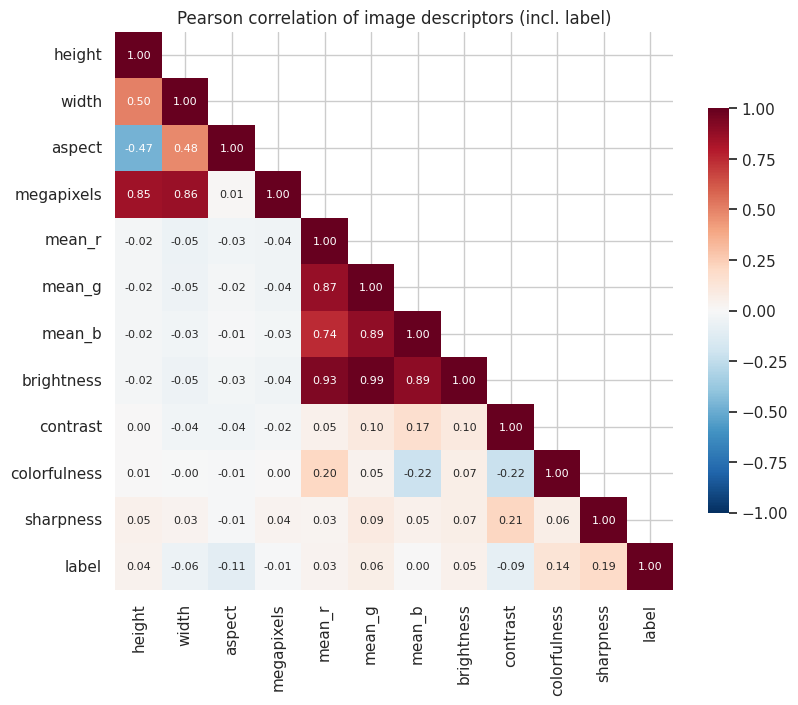

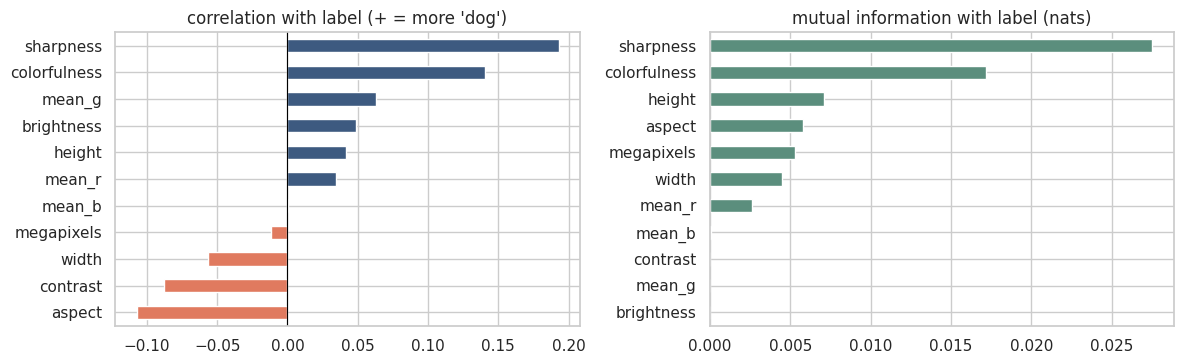

strongly correlated feature pairs (|r| > 0.8):
height      megapixels    0.85
megapixels  width         0.86
mean_g      mean_r        0.87
mean_b      mean_g        0.89
brightness  mean_r        0.93
            mean_g        0.99
            mean_b        0.89


In [35]:
from sklearn.feature_selection import mutual_info_classif

corr = df[FEATURES + ["label"]].corr(method="pearson")
fig, ax = plt.subplots(figsize=(9, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.7}, annot_kws={"size": 8}, ax=ax)
ax.set_title("Pearson correlation of image descriptors (incl. label)")
save_fig("correlation"); plt.show()

label_corr = corr["label"].drop("label")
mi = pd.Series(mutual_info_classif(df[FEATURES], df["label"], random_state=SEED), index=FEATURES)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
label_corr.sort_values().plot.barh(ax=axes[0], color=[CLASS_COLORS["dog"] if v > 0 else CLASS_COLORS["cat"] for v in label_corr.sort_values()])
axes[0].set_title("correlation with label (+ = more 'dog')"); axes[0].axvline(0, color="black", lw=0.8)
mi.sort_values().plot.barh(ax=axes[1], color="#5B8E7D"); axes[1].set_title("mutual information with label (nats)")
plt.tight_layout(); save_fig("label_corr"); plt.show()

strong_pairs = (corr.drop(index="label", columns="label").where(~np.eye(len(FEATURES), dtype=bool))
                .stack().loc[lambda s: s.abs() > 0.8])
print("strongly correlated feature pairs (|r| > 0.8):")
print(strong_pairs[strong_pairs.index.get_level_values(0) < strong_pairs.index.get_level_values(1)].round(2).to_string())
RESULTS["eda"] = {
    "features": FEATURES, "corr": corr.round(3).values.tolist(), "corr_labels": FEATURES + ["label"],
    "label_corr": label_corr.round(4).to_dict(), "mutual_info": mi.round(4).to_dict(),
    "describe": df[FEATURES].describe().T.round(3).to_dict(orient="index"),
    "tests": tests[["cat_median", "dog_median", "effect_size", "p_value"]].round(4).to_dict(orient="index"),
}

### Observations — correlation
* **Redundancy between features:** brightness vs mean green r = 0.99, megapixels vs width r = 0.86, height vs megapixels r = 0.84. In a tabular model we would drop or combine these (multicollinearity).
* **Link to the label is weak:** the strongest correlation is **sharpness** with r = +0.193, i.e. it explains only 3.7 % of the label variance on its own. Mutual information (which also captures non-linear relations) ranks the features similarly and stays close to zero.
* Conclusion: global image statistics carry very little class information — the signal is in local shapes and textures, which motivates a CNN.

In [36]:
# Store histogram data for the project website (bin edges + counts per class)
def hist_by_class(col, bins=40, log=False, clip=None):
    v = np.log10(df[col] + 1) if log else df[col]
    lo, hi = (v.quantile(0.005), v.quantile(0.995)) if clip else (v.min(), v.max())
    edges = np.linspace(lo, hi, bins + 1)
    return {"edges": edges.round(4).tolist(),
            **{c: np.histogram(v[df["class"] == c].clip(lo, hi), edges)[0].tolist() for c in class_names}}
RESULTS["eda"]["hist"] = {c: hist_by_class(c, log=(c == "sharpness"), clip=True) for c in uni}
RESULTS["eda"]["top_sizes"] = top_sizes.to_dict()
RESULTS["eda"]["n_images"] = int(len(df))

## 6.7 EDA summary → consequences for the pipeline
1. **Clean-up needed is small:** remove the near-blank image(s) and redundant duplicate copies (28 images in total); everything else is valid.
2. **Balanced target** → accuracy (plus ROC-AUC) as the main metrics; stratified splitting keeps the balance.
3. **Variable size and framing** → resize to 160×160, and use augmentation (flip/rotate/zoom) so the model sees varied framings.
4. **Duplicates exist** → split grouped by perceptual hash to avoid leakage.
5. **Hand-made statistics are weak predictors** (max |r| = 0.19) → expect classical ML to plateau far below a CNN that learns its own features. Section 9 tests this.

# 7. Data cleaning & leakage-safe split
* **Remove**: near-blank images, extra copies of duplicates, and every copy of duplicates whose labels
  disagree.
* **Split 80 / 10 / 10** into train / validation / test with `StratifiedGroupKFold`:
  *stratified* keeps the cat/dog ratio equal in every split; *grouped by perceptual hash* guarantees that
  look-alike images never sit on both sides of a split.

| Split | Used for |
|---|---|
| **train** | fitting the weights |
| **validation** | model selection, hyperparameter tuning, early stopping, threshold choice |
| **test** | touched **once** at the very end to report the final quality |

In [37]:
from sklearn.model_selection import StratifiedGroupKFold

remove = df["duplicate_copy"] | df["conflict_dup"] | df["near_blank"]
clean = df[~remove].copy()
print(f"removed {remove.sum()} images  ->  {len(clean):,} remain")

sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
clean["split"] = "train"
folds = list(sgkf.split(clean, clean["label"], groups=clean["hash"]))
clean.iloc[folds[0][1], clean.columns.get_loc("split")] = "test"
clean.iloc[folds[1][1], clean.columns.get_loc("split")] = "val"

# sanity checks: no hash group crosses splits, class ratio preserved
assert clean.groupby("hash")["split"].nunique().max() == 1
split_table = pd.crosstab(clean["split"], clean["class"]).reindex(["train", "val", "test"])
split_table["total"] = split_table.sum(axis=1)
split_table["% dog"] = (split_table["dog"] / split_table["total"] * 100).round(1)
RESULTS["split"] = {s: {k: int(v) for k, v in split_table.loc[s, ["cat", "dog", "total"]].items()}
                    for s in split_table.index}
RESULTS["split"]["removed"] = int(remove.sum())

# Saved training stages are only valid for the split they were trained on. Library versions can change how
# StratifiedGroupKFold shuffles, so a cache copied from another machine may belong to a different split.
import hashlib
SPLIT_FP = hashlib.md5("|".join(sorted(clean.loc[clean["split"] == "test", "filename"])).encode()).hexdigest()[:12]
fp_file = os.path.join(CACHE_DIR, "split_fingerprint.txt")
old_fp = open(fp_file).read().strip() if os.path.exists(fp_file) else None
has_stages = any(f.endswith((".json", ".keras")) for f in os.listdir(CACHE_DIR))
if REUSE_SAVED and has_stages and old_fp != SPLIT_FP:
    print("saved training stages belong to a different data split -> they will be retrained")
    REUSE_SAVED = False
with open(fp_file, "w") as fh:
    fh.write(SPLIT_FP)
print("split fingerprint:", SPLIT_FP)
split_table

removed 28 images  ->  23,234 remain


class,cat,dog,total,% dog
split,,,,
train,9285,9302,18587,50.0
val,1185,1138,2323,49.0
test,1170,1154,2324,49.7


# 8. Preprocessing & augmentation pipeline
`tf.data` pipeline, per split:

1. look up the split of every file (hash table `filename → split`) and keep only that split;
2. decode the JPEG (TFDS stores encoded bytes; we skip decoding until after the filter → faster);
3. **resize** to 160×160 and store as `uint8`; **cache** in memory (decoded once, reused every epoch);
4. **shuffle** (train only), **batch** (32) and **prefetch** (overlap data loading with training).

**Rescaling** (0–255 → model range) and **augmentation** live *inside* the model, so the saved model takes
raw images and augmentation runs only during training (and on the GPU when available).

In [38]:
split_id = {"train": 0, "val": 1, "test": 2}
table = tf.lookup.StaticHashTable(
    tf.lookup.KeyValueTensorInitializer(tf.constant(clean["filename"].values),
                                        tf.constant(clean["split"].map(split_id).values, dtype=tf.int64)),
    default_value=-1)                               # removed images -> -1 -> filtered out

encoded_ds = tfds.load("cats_vs_dogs", split="train", shuffle_files=False,
                       decoders={"image": tfds.decode.SkipDecoding()})

def decode_resize(ex):
    img = tf.io.decode_image(ex["image"], channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.cast(tf.round(img), tf.uint8), tf.cast(ex["label"], tf.float32), ex["image/filename"]

def make_split(name, shuffle=False):
    k = split_id[name]
    ds = (encoded_ds.filter(lambda ex: table.lookup(ex["image/filename"]) == k)
          .map(decode_resize, num_parallel_calls=AUTOTUNE).cache())
    triples = ds                                                  # keeps filenames (for error analysis)
    if shuffle:                                                   # shuffle uint8 images: 4x less memory than float32
        ds = ds.shuffle(1000, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda x, y, f: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(2), triples

train_ds, train_triples = make_split("train", shuffle=True)
val_ds, val_triples = make_split("val")
test_ds, test_triples = make_split("test")

t0 = time.perf_counter()
for _ in train_ds: pass                                         # fills the caches once
for _ in val_ds: pass
for _ in test_ds: pass
print(f"decoded + cached all splits in {time.perf_counter() - t0:.0f}s")
images, labels = next(iter(train_ds))
print("batch:", images.shape, images.dtype, "| labels:", labels.numpy()[:10],
      "| pixel range:", float(tf.reduce_min(images)), "-", float(tf.reduce_max(images)))

decoded + cached all splits in 32s
batch: (32, 160, 160, 3) <dtype: 'float32'> | labels: [1. 0. 1. 0. 0. 1. 1. 0. 1. 0.] | pixel range: 0.0 - 255.0


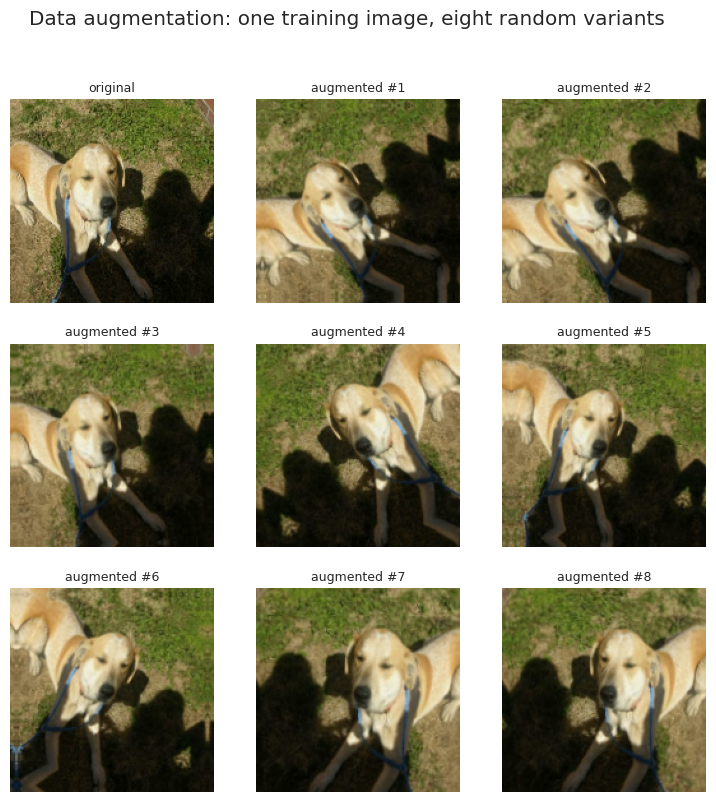

In [39]:
def make_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),       # ± 10 % of a full turn = ± 36°
        layers.RandomZoom(0.1),
    ], name="augmentation")

data_augmentation = make_augmentation()

image = images[0]
plt.figure(figsize=(9, 9))
for i in range(9):
    aug = image[None] if i == 0 else data_augmentation(image[None], training=True)
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(np.clip(aug[0].numpy(), 0, 255).astype("uint8"))
    plt.title("original" if i == 0 else f"augmented #{i}", fontsize=9); plt.axis("off")
plt.suptitle("Data augmentation: one training image, eight random variants")
save_fig("augmentation"); plt.show()

# 9. Classical-ML baselines
Before any deep learning: **how good can a model get using the hand-made features from the EDA?**
This sets the bar a neural network has to beat and tests the EDA conclusion that global statistics carry
little signal.

| Baseline | Input |
|---|---|
| Majority class | nothing — always predicts the most common class |
| Logistic regression | 11 image descriptors + 24 colour-histogram bins |
| Random forest | same 35 features (captures non-linear interactions) |
| PCA + logistic regression | raw 32×32 grayscale pixels (1 024 values → 100 principal components) |

In [40]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score

tab = np.hstack([df[FEATURES].values, hists])          # 11 descriptors + 24 histogram bins
pix = thumbs32.reshape(len(df), -1).astype(np.float32) / 255.0
pos = {s: clean.index[clean["split"] == s].values for s in ["train", "val", "test"]}
y = df["label"].values

baselines = {
    "Majority class": (DummyClassifier(strategy="most_frequent"), tab),
    "Logistic regression (features)": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), tab),
    "Random forest (features)": (RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED), tab),
    "PCA + logistic regression (pixels)": (make_pipeline(StandardScaler(), PCA(100, random_state=SEED), LogisticRegression(max_iter=2000)), pix),
}
base_rows = []
for name, (model, X) in baselines.items():
    t0 = time.perf_counter()
    model.fit(X[pos["train"]], y[pos["train"]])
    p_val = model.predict_proba(X[pos["val"]])[:, 1]
    base_rows.append(dict(model=name, val_accuracy=accuracy_score(y[pos["val"]], p_val >= 0.5),
                          val_auc=roc_auc_score(y[pos["val"]], p_val) if len(set(p_val)) > 1 else 0.5,
                          fit_seconds=time.perf_counter() - t0))
baseline_df = pd.DataFrame(base_rows).set_index("model")
RESULTS["baselines"] = baseline_df.round(4).to_dict(orient="index")

rf = baselines["Random forest (features)"][0]
imp = pd.Series(rf.feature_importances_, index=FEATURES + [f"hist_{c}" for c in hist_cols]).sort_values(ascending=False)
print("top random-forest features:", imp.head(6).round(3).to_dict())
baseline_df.round(3)

top random-forest features: {'sharpness': 0.085, 'colorfulness': 0.055, 'hist_G0': 0.034, 'hist_B0': 0.031, 'hist_B2': 0.031, 'hist_R0': 0.029}


,val_accuracy,val_auc,fit_seconds
model,,,
Majority class,0.490,0.500,0.004
Logistic regression (features),0.619,0.676,0.612
Random forest (features),0.652,0.715,31.507
PCA + logistic regression (pixels),0.590,0.616,3.997


### Observations — baselines
* Best classical model: **Random forest (features)** with **65.2 %** validation accuracy (AUC 0.715); the majority-class floor is 49.0 %.
* Ranking: Random forest (features) 65.2 %, Logistic regression (features) 61.9 %, PCA + logistic regression (pixels) 59.0 %, Majority class 49.0 %.
* This confirms the EDA: global features help a little but leave roughly 3 in 10 images misclassified. For reference, Golle (2008) reached 82.7 % per image on Asirra with far richer colour and texture features — still far from what CNNs achieve.

# 10. Model selection

### Design decisions shared by every candidate
| Decision | Choice | Why |
|---|---|---|
| Input | 160×160×3, raw 0–255 | fixed size required; scaling happens inside the model |
| Output layer | `Dense(1, activation="sigmoid")` | one probability $P(\text{dog})$ for a binary task |
| Loss | binary cross-entropy | the standard (log-likelihood) loss for a sigmoid output |
| Optimizer | Adam, lr = 1e-3 | robust default; tuned in Section 11 |
| Metrics | accuracy (classes are balanced), ROC-AUC | accuracy is meaningful at ~50/50 |
| Stopping | `EarlyStopping(val_loss, patience=3, restore_best_weights)` | stops before overfitting |

### Candidates — increasing capacity and prior knowledge
**A. Simple CNN (from scratch)** — 3 × [Conv 3×3 → ReLU → MaxPool] with 32/64/128 filters → Flatten →
Dense(128) → Dense(1). The textbook first CNN; no regularisation, so we expect overfitting.

**B. Deeper regularised CNN (from scratch)** — augmentation + 4 × [Conv → BatchNorm → ReLU → MaxPool]
(32/64/128/256) → GlobalAveragePooling → Dropout(0.3) → Dense(1). BatchNorm stabilises training,
global pooling replaces the huge Flatten→Dense weight matrix, dropout + augmentation fight overfitting.

**C. Transfer learning — MobileNetV2 (ImageNet)** — augmentation → rescale to [−1, 1] → *frozen*
MobileNetV2 feature extractor → GlobalAveragePooling → Dropout(0.2) → Dense(1).
MobileNetV2 already knows fur, eyes and ears from 1.2 M ImageNet photos (which include many cat and dog
breeds); we only train the small head. It is light (≈ 2.3 M parameters), fast on CPU and phones.

All three are trained with the **same epoch budget** and compared on the **validation** split.
On a CPU-only machine the screening uses the same fixed subset of 4 000 training images for every
candidate (training the from-scratch deeper CNN on everything costs ≈ 11 min per epoch on a laptop);
the winner is then trained on the full training set in Section 12. On a GPU the full set is used.

In [41]:
def compile_binary(model, lr=1e-3):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model

def simple_cnn():
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1 / 255)(inputs)
    for f in (32, 64, 128):
        x = layers.Conv2D(f, 3, activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    return keras.Model(inputs, layers.Dense(1, activation="sigmoid")(x), name="A_simple_cnn")

def deeper_cnn():
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = make_augmentation()(inputs)
    x = layers.Rescaling(1 / 255)(x)
    for f in (32, 64, 128, 256):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    return keras.Model(inputs, layers.Dense(1, activation="sigmoid")(x), name="B_deeper_cnn")

def mobilenet_base():
    base = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = False
    return base

def make_head(dropout=0.2, hidden=0, name="head"):
    head = [layers.GlobalAveragePooling2D()]
    if hidden:
        head += [layers.Dropout(dropout), layers.Dense(hidden, activation="relu")]
    head += [layers.Dropout(dropout), layers.Dense(1, activation="sigmoid")]
    return keras.Sequential(head, name=name)

def transfer_model(base, head, name="C_mobilenetv2_transfer", augmentation=None):
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = (augmentation or make_augmentation())(inputs)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)        # MobileNetV2 expects pixels in [-1, 1]
    x = base(x, training=False)                          # keep BatchNorm in inference mode (matters for fine-tuning)
    return keras.Model(inputs, head(x), name=name)

candidates = {"A_simple_cnn": simple_cnn,
              "B_deeper_cnn": deeper_cnn,
              "C_mobilenetv2_transfer": lambda: transfer_model(mobilenet_base(), make_head())}
for name, build in candidates.items():
    m = build()
    print(f"{name:<24} parameters: {m.count_params():>10,}   trainable: {sum(int(np.prod(w.shape)) for w in m.trainable_weights):>10,}")
simple_cnn().summary()
keras.backend.clear_session(); gc.collect()

A_simple_cnn             parameters:  5,401,921   trainable:  5,401,921
B_deeper_cnn             parameters:    390,113   trainable:    389,153
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
C_mobilenetv2_transfer   parameters:  2,259,265   trainable:      1,281


Model: "A_simple_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,401,921 (20.61 MB)

 Trainable params: 5,401,921 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

0

In [42]:
early_stop = lambda: keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

select_train = train_triples if SELECT_SUBSET is None else train_triples.take(SELECT_SUBSET)
select_train_ds = (select_train.shuffle(1000, seed=SEED).map(lambda x, y, f: (tf.cast(x, tf.float32), y))
                   .batch(BATCH_SIZE).prefetch(2))
print("training images used for model selection:", sum(int(b[1].shape[0]) for b in select_train_ds))

sel_saved = json.load(open(saved("selection.json"))) if saved("selection.json") else {"selection": [], "histories": {}}
selection, histories = sel_saved["selection"], sel_saved["histories"]      # candidates finished in an earlier run
todo = [name for name in candidates if name not in histories]
if not todo:
    print("loaded saved model-selection results (set REUSE_SAVED = False to retrain)")
elif histories:
    print("reusing saved results for", list(histories), "- training", todo)
if todo:
    for name in todo:
        build = candidates[name]
        keras.utils.set_random_seed(SEED)
        model = compile_binary(build())
        t0 = time.perf_counter()
        h = model.fit(select_train_ds, validation_data=val_ds, epochs=BUDGET["select_epochs"],
                      callbacks=[early_stop(), ProgressLog(name)], verbose=2)
        secs = time.perf_counter() - t0
        hh = {k: [float(v) for v in vals] for k, vals in h.history.items()}
        histories[name] = hh
        best = int(np.argmin(hh["val_loss"]))
        selection.append(dict(model=name, params=int(model.count_params()),
                              trainable=sum(int(np.prod(w.shape)) for w in model.trainable_weights),
                              best_epoch=best + 1, train_accuracy=hh["accuracy"][best],
                              val_accuracy=hh["val_accuracy"][best], val_auc=hh["val_auc"][best],
                              val_loss=hh["val_loss"][best], seconds=secs))
        print(f"--> {name}: val_acc={selection[-1]['val_accuracy']:.4f}  ({secs / 60:.1f} min)\n")
        del model, h; keras.backend.clear_session(); gc.collect()     # release memory before the next candidate
        json.dump({"selection": selection, "histories": histories}, open(os.path.join(CACHE_DIR, "selection.json"), "w"))
    progress("model selection done")
selection = sorted(selection, key=lambda r: list(candidates).index(r["model"]))
histories = {name: histories[name] for name in candidates}

selection_df = pd.DataFrame(selection).set_index("model")
selection_df["overfit_gap"] = selection_df["train_accuracy"] - selection_df["val_accuracy"]
RESULTS["selection"] = {"table": selection_df.round(4).to_dict(orient="index"), "histories": histories}
selection_df.round(4)

training images used for model selection: 18587
Epoch 1/12
581/581 - 33s - 57ms/step - accuracy: 0.6832 - auc: 0.7597 - loss: 0.5785 - val_accuracy: 0.7417 - val_auc: 0.8623 - val_loss: 0.4972
Epoch 2/12
581/581 - 16s - 28ms/step - accuracy: 0.7942 - auc: 0.8798 - loss: 0.4354 - val_accuracy: 0.7964 - val_auc: 0.8852 - val_loss: 0.4554
Epoch 3/12
581/581 - 17s - 29ms/step - accuracy: 0.8471 - auc: 0.9268 - loss: 0.3446 - val_accuracy: 0.8102 - val_auc: 0.8932 - val_loss: 0.4505
Epoch 4/12
581/581 - 17s - 29ms/step - accuracy: 0.8929 - auc: 0.9617 - loss: 0.2516 - val_accuracy: 0.8188 - val_auc: 0.8995 - val_loss: 0.4664
Epoch 5/12
581/581 - 17s - 29ms/step - accuracy: 0.9401 - auc: 0.9863 - loss: 0.1506 - val_accuracy: 0.8325 - val_auc: 0.9070 - val_loss: 0.5744
Epoch 6/12
581/581 - 17s - 29ms/step - accuracy: 0.9705 - auc: 0.9960 - loss: 0.0815 - val_accuracy: 0.8295 - val_auc: 0.9012 - val_loss: 0.6479
--> A_simple_cnn: val_acc=0.8102  (1.9 min)

Epoch 1/12
581/581 - 48s - 82ms/step 

,params,trainable,best_epoch,train_accuracy,val_accuracy,val_auc,val_loss,seconds,overfit_gap
model,,,,,,,,,
A_simple_cnn,5401921,5401921,3,0.8471,0.8102,0.8932,0.4505,116.5393,0.0369
B_deeper_cnn,390113,389153,12,0.8507,0.8601,0.9364,0.3333,480.5003,-0.0094
C_mobilenetv2_transfer,2259265,1281,4,0.9687,0.9854,0.9985,0.0449,253.5522,-0.0167


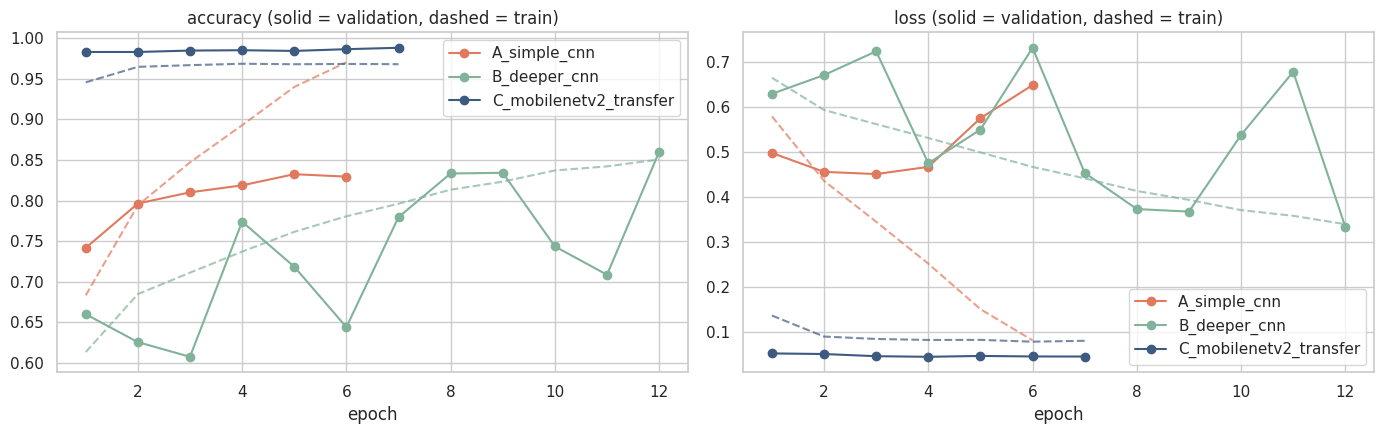

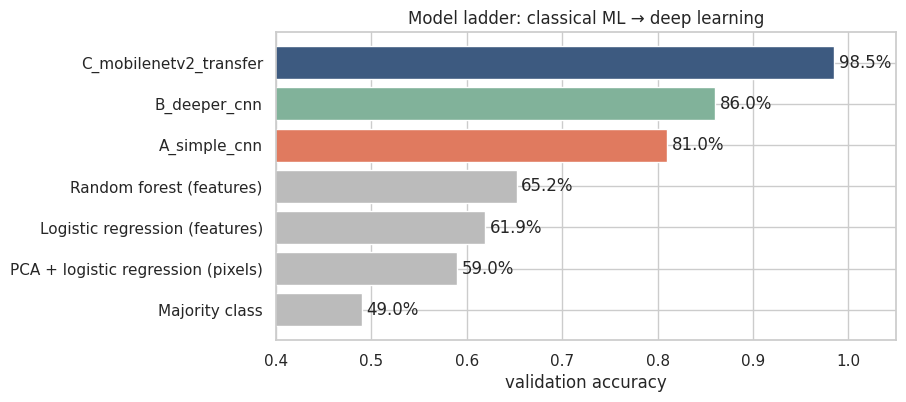

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
colors = dict(zip(candidates, ["#E07A5F", "#81B29A", "#3D5A80"]))
for name, hist in histories.items():
    ep = np.arange(1, len(hist["loss"]) + 1)
    axes[0].plot(ep, hist["accuracy"], "--", color=colors[name], alpha=0.7)
    axes[0].plot(ep, hist["val_accuracy"], "-o", color=colors[name], label=name)
    axes[1].plot(ep, hist["loss"], "--", color=colors[name], alpha=0.7)
    axes[1].plot(ep, hist["val_loss"], "-o", color=colors[name], label=name)
axes[0].set_title("accuracy (solid = validation, dashed = train)"); axes[1].set_title("loss (solid = validation, dashed = train)")
for ax in axes: ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); save_fig("selection_curves"); plt.show()

# add the classical baselines for one overall comparison
ladder = pd.concat([baseline_df["val_accuracy"], selection_df["val_accuracy"]]).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ladder.index, ladder.values, color=["#BBBBBB"] * len(baseline_df) + [colors[n] for n in ladder.index if n in colors])
for i, v in enumerate(ladder.values): ax.text(v + 0.005, i, f"{v:.1%}", va="center")
ax.set_xlim(0.4, 1.05); ax.set_xlabel("validation accuracy"); ax.set_title("Model ladder: classical ML → deep learning")
save_fig("selection_compare"); plt.show()

### Selection rule
Pick the candidate with the **highest validation accuracy**; if another candidate is within
**0.5 percentage points**, prefer the one with **fewer trainable parameters** (simpler, cheaper,
less risk of overfitting the validation set).

In [44]:
best_acc = selection_df["val_accuracy"].max()
shortlist = selection_df[selection_df["val_accuracy"] >= best_acc - 0.005]
WINNER = shortlist.sort_values("trainable").index[0]
RESULTS["selection"]["winner"] = WINNER
print("shortlist:", list(shortlist.index), "\nselected model family:", WINNER)

shortlist: ['C_mobilenetv2_transfer'] 
selected model family: C_mobilenetv2_transfer


### Observations — model selection
| | trainable params | train acc. | val. acc. | gap |
|---|---:|---:|---:|---:|
| A_simple_cnn | 5,401,921 | 84.7 % | 81.0 % | +3.7 pp |
| B_deeper_cnn | 389,153 | 85.1 % | 86.0 % | -0.9 pp |
| C_mobilenetv2_transfer | 1,281 | 96.9 % | 98.5 % | -1.7 pp |

* **C_mobilenetv2_transfer** is selected: 98.5 % validation accuracy, 12.5 pp ahead of B_deeper_cnn, while training only 1,281 weights.
* The **simple CNN** (5,401,921 parameters, mostly in the Flatten→Dense layer) overfits: by its last epoch it scores 97.0 % on training data but only 83.0 % on validation, and its best validation epoch was 3 — early stopping kept those weights.
* Both from-scratch CNNs beat every classical baseline.
* The **deeper regularised CNN** has far fewer parameters (390,113). It ends at 86.0 % (best epoch 12 of 12), ahead of the simple CNN, with a small train/validation gap; its validation score jumps between epochs (batch-normalisation statistics settle slowly) and it was still improving.
* Transfer learning wins because MobileNetV2 already learned edges, fur textures, eyes and ears from 1.2 M ImageNet images; a single linear layer on top of its features is enough to separate cats from dogs.

# 11. Hyperparameter tuning
We tune the **classification head of the transfer-learning model** — the part we actually train.

**Speed trick:** the frozen MobileNetV2 gives the *same* output for the same image, so we run it **once**
on every train/validation image and cache the 1 280-dimensional feature vectors. Each trial then trains
only the tiny head in seconds instead of minutes. (Augmentation is off for the cached features; it is
switched back on for the final model.)

**Search space — full grid, 3 × 3 × 2 × 2 = 36 trials**

| Hyperparameter | Values | Effect |
|---|---|---|
| learning rate | 1e-2, 1e-3, 1e-4 | step size of Adam |
| dropout | 0.0, 0.2, 0.5 | regularisation strength |
| hidden layer | none, Dense(256) | head capacity |
| batch size | 64, 256 | gradient noise vs speed |

Every trial uses early stopping on validation loss (patience 3, max 20 epochs).
**Decision rule:** best validation accuracy, ties (< 0.1 pp) broken by lower validation loss.

In [45]:
import itertools

feature_extractor = keras.Sequential([layers.Rescaling(1 / 127.5, offset=-1), mobilenet_base(),
                                      layers.GlobalAveragePooling2D()], name="feature_extractor")
t0 = time.perf_counter()
def extract(triples):
    ds = triples.map(lambda x, y, f: (tf.cast(x, tf.float32), y)).batch(64).prefetch(AUTOTUNE)
    feats, ys = [], []
    for xb, yb in ds:
        feats.append(feature_extractor(xb, training=False).numpy()); ys.append(yb.numpy())
    return np.concatenate(feats), np.concatenate(ys)
if saved("tuning.json"):
    print("tuning results are saved - feature extraction skipped")
else:
    F_train, Y_train = extract(train_triples)
    F_val, Y_val = extract(val_triples)
    print(f"cached features {F_train.shape} / {F_val.shape} in {time.perf_counter() - t0:.0f}s")
    progress("feature extraction done")
del feature_extractor; keras.backend.clear_session(); gc.collect()

cached features (18587, 1280) / (2323, 1280) in 56s


0

In [46]:
grid = dict(lr=[1e-2, 1e-3, 1e-4], dropout=[0.0, 0.2, 0.5], hidden=[0, 256], batch=[64, 256])
if saved("tuning.json"):
    tun_saved = json.load(open(saved("tuning.json")))
    trials, curves = tun_saved["trials"], tun_saved["curves"]
    print("loaded saved tuning results (set REUSE_SAVED = False to re-run the search)")
else:
    trials, curves = [], {}
    t0 = time.perf_counter()
    for i, (lr, dr, hid, bs) in enumerate(itertools.product(*grid.values()), start=1):
        keras.utils.set_random_seed(SEED)
        head = keras.Sequential([keras.Input((F_train.shape[1],))]
                                + ([layers.Dropout(dr), layers.Dense(hid, activation="relu")] if hid else [])
                                + [layers.Dropout(dr), layers.Dense(1, activation="sigmoid")])
        compile_binary(head, lr)
        h = head.fit(F_train, Y_train, validation_data=(F_val, Y_val), epochs=BUDGET["tune_epochs"],
                     batch_size=bs, callbacks=[early_stop()], verbose=0)
        hh = {k: [float(v) for v in vals] for k, vals in h.history.items()}
        b = int(np.argmin(hh["val_loss"]))
        trials.append(dict(lr=lr, dropout=dr, hidden=hid, batch=bs, epochs=len(hh["loss"]),
                           val_accuracy=hh["val_accuracy"][b], val_loss=hh["val_loss"][b],
                           val_auc=hh["val_auc"][b], train_accuracy=hh["accuracy"][b]))
        curves[f"lr={lr}|dr={dr}|h={hid}|bs={bs}"] = hh["val_loss"]
        del head, h; keras.backend.clear_session(); gc.collect()
        progress(f"tuning trial {i}/36: lr={lr} dropout={dr} hidden={hid} batch={bs} -> val_accuracy={trials[-1]['val_accuracy']:.4f}")
    print(f"{len(trials)} trials in {time.perf_counter() - t0:.0f}s")
    json.dump({"trials": trials, "curves": curves}, open(os.path.join(CACHE_DIR, "tuning.json"), "w"))

tuning = pd.DataFrame(trials)
tuning["rank_key"] = tuning["val_accuracy"].round(3)
tuning = tuning.sort_values(["rank_key", "val_loss"], ascending=[False, True]).drop(columns="rank_key").reset_index(drop=True)
BEST_HP = tuning.iloc[0][["lr", "dropout", "hidden", "batch"]].to_dict()
BEST_HP = dict(lr=float(BEST_HP["lr"]), dropout=float(BEST_HP["dropout"]), hidden=int(BEST_HP["hidden"]), batch=int(BEST_HP["batch"]))
RESULTS["tuning"] = {"grid": grid, "trials": tuning.round(5).to_dict(orient="records"), "best": BEST_HP}
print("best hyperparameters:", BEST_HP)
tuning.head(10).round(4)

36 trials in 405s
best hyperparameters: {'lr': 0.001, 'dropout': 0.5, 'hidden': 256, 'batch': 64}


,lr,dropout,hidden,batch,epochs,val_accuracy,val_loss,val_auc,train_accuracy
0,0.0010,0.5,256,64,13,0.9875,0.0328,0.9994,0.9853
1,0.0100,0.5,256,256,8,0.9879,0.0360,0.9989,0.9792
2,0.0010,0.2,256,64,6,0.9875,0.0416,0.9975,0.9870
3,0.0100,0.2,256,64,6,0.9879,0.0448,0.9967,0.9798
4,0.0010,0.5,0,64,8,0.9871,0.0431,0.9982,0.9802
5,0.0100,0.5,0,256,5,0.9871,0.0456,0.9973,0.9774
6,0.0100,0.2,0,256,5,0.9867,0.0475,0.9968,0.9828
7,0.0001,0.5,256,64,13,0.9858,0.0400,0.9982,0.9807
8,0.0100,0.2,256,256,6,0.9858,0.0406,0.9983,0.9850
9,0.0001,0.5,256,256,20,0.9858,0.0415,0.9985,0.9794


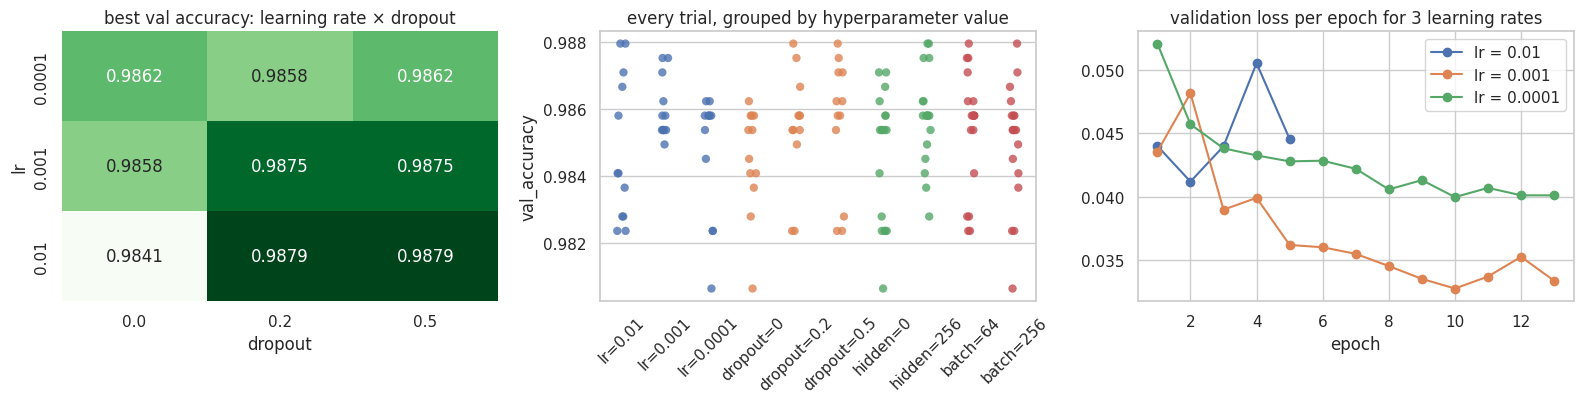

mean val accuracy over trials
hyperparameter value                                
lr             0.0001                         0.9847
               0.001                          0.9860
               0.01                           0.9848
dropout        0                              0.9845
               0.2                            0.9854
               0.5                            0.9855
hidden         0                              0.9846
               256                            0.9857
batch          64                             0.9854
               256                            0.9850

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
pivot = tuning.pivot_table(index="lr", columns="dropout", values="val_accuracy", aggfunc="max")
sns.heatmap(pivot, annot=True, fmt=".4f", cmap="Greens", ax=axes[0], cbar=False)
axes[0].set_title("best val accuracy: learning rate × dropout")

long = tuning.melt(id_vars=["val_accuracy"], value_vars=["lr", "dropout", "hidden", "batch"], var_name="hp")
long["value"] = long["hp"] + "=" + long["value"].map(lambda v: f"{v:g}")
order = [f"{hp}={v:g}" for hp in ["lr", "dropout", "hidden", "batch"] for v in grid[hp]]
sns.stripplot(data=long, x="value", y="val_accuracy", hue="hp", order=order, ax=axes[1], dodge=False, size=6, alpha=0.8, legend=False)
axes[1].set_title("every trial, grouped by hyperparameter value"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=45)

for lr in grid["lr"]:
    key = f"lr={lr}|dr={BEST_HP['dropout']}|h={BEST_HP['hidden']}|bs={BEST_HP['batch']}"
    axes[2].plot(np.arange(1, len(curves[key]) + 1), curves[key], "-o", label=f"lr = {lr}")
axes[2].set_title("validation loss per epoch for 3 learning rates"); axes[2].set_xlabel("epoch"); axes[2].legend()
plt.tight_layout(); save_fig("tuning"); plt.show()

effects = {hp: tuning.groupby(hp)["val_accuracy"].mean().round(4).to_dict() for hp in ["lr", "dropout", "hidden", "batch"]}
RESULTS["tuning"]["effects"] = {hp: {str(k): v for k, v in d.items()} for hp, d in effects.items()}
RESULTS["tuning"]["lr_curves"] = {str(lr): curves[f"lr={lr}|dr={BEST_HP['dropout']}|h={BEST_HP['hidden']}|bs={BEST_HP['batch']}"] for lr in grid["lr"]}
pd.DataFrame([(hp, f"{k:g}", v) for hp, d in effects.items() for k, v in d.items()],
             columns=["hyperparameter", "value", "mean val accuracy over trials"]).set_index(["hyperparameter", "value"])

### Observations — hyperparameter tuning
* **Chosen:** learning rate **0.001**, dropout **0.5**, hidden layer **256**, batch size **64** → 98.75 % validation accuracy (val. loss 0.0328).
* **The head is barely sensitive to its settings:** all 36 trials land between 98.06 % and 98.80 %. Once MobileNetV2 provides the features, cats and dogs are almost linearly separable.
* Mean validation accuracy per value — learning rate: 0.0001: 98.47 %, 0.001: 98.60 %, 0.01: 98.48 %; dropout: 0.0: 98.45 %, 0.2: 98.54 %, 0.5: 98.55 %; hidden layer: 0: 98.46 %, 256: 98.57 %; batch: 64: 98.54 %, 256: 98.50 %. A hidden layer and some dropout help slightly; every difference is a few tenths of a percent.
* The learning rate mostly changes **speed**: with lr = 0.0001 the head needs 13 epochs to settle, with lr = 0.01 the validation loss is noisier (right-hand plot).

# 12. Final training + fine-tuning
**Stage 1 – train the head** (base frozen, augmentation on) with the tuned hyperparameters.
Callbacks: `EarlyStopping`, `ReduceLROnPlateau` (halve the learning rate when validation loss stalls) and
`ModelCheckpoint` (keep the best weights on disk).

**Stage 2 – fine-tune**: unfreeze the **top layers of MobileNetV2** (from layer 100 of 154 upwards) and
continue with a **very small learning rate (1e-5)**, so the pretrained features adapt slightly to cats and
dogs without being destroyed. (A larger rate such as 1e-3 wipes out the ImageNet features within one epoch —
validation accuracy drops to coin-flip level.) BatchNorm layers stay in inference mode (`training=False`) — updating their
statistics with small batches would wreck the pretrained weights.

In [48]:
FINAL_MODEL_PATH = os.path.join(RESULTS_DIR, "cats_vs_dogs_mobilenetv2.keras")
FINAL_TRAINED = bool(saved("final_history.json")) and os.path.exists(FINAL_MODEL_PATH)
if FINAL_TRAINED:
    final_model = keras.models.load_model(FINAL_MODEL_PATH)
    fh_saved = json.load(open(saved("final_history.json")))
    hist1, hist2 = fh_saved["stage1"], fh_saved["stage2"]
    print("loaded the saved final model (set REUSE_SAVED = False to retrain)")
else:
    keras.utils.set_random_seed(SEED)
    base = mobilenet_base()
    head = make_head(dropout=BEST_HP["dropout"], hidden=BEST_HP["hidden"])
    final_model = compile_binary(transfer_model(base, head, name="final_mobilenetv2"), BEST_HP["lr"])
    train_ds_final = train_ds.unbatch().batch(BEST_HP["batch"]).prefetch(AUTOTUNE)
    ckpt_path = os.path.join(CACHE_DIR, "best_checkpoint.keras")
    callbacks = [early_stop(), ProgressLog("final"),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-6),
                 keras.callbacks.ModelCheckpoint(ckpt_path, monitor="val_loss", save_best_only=True)]
    t0 = time.perf_counter()
    h1 = final_model.fit(train_ds_final, validation_data=val_ds, epochs=BUDGET["head_epochs"], callbacks=callbacks, verbose=2)
    hist1 = {k: [float(v) for v in vals] for k, vals in h1.history.items()}
    print(f"stage 1: {time.perf_counter() - t0:.0f}s")

Epoch 1/10
291/291 - 29s - 100ms/step - accuracy: 0.9433 - auc: 0.9870 - loss: 0.1455 - val_accuracy: 0.9841 - val_auc: 0.9987 - val_loss: 0.0482 - learning_rate: 0.0010
Epoch 2/10
291/291 - 22s - 77ms/step - accuracy: 0.9578 - auc: 0.9923 - loss: 0.1082 - val_accuracy: 0.9867 - val_auc: 0.9987 - val_loss: 0.0445 - learning_rate: 0.0010
Epoch 3/10
291/291 - 22s - 75ms/step - accuracy: 0.9587 - auc: 0.9930 - loss: 0.1051 - val_accuracy: 0.9841 - val_auc: 0.9989 - val_loss: 0.0434 - learning_rate: 0.0010
Epoch 4/10
291/291 - 22s - 76ms/step - accuracy: 0.9612 - auc: 0.9939 - loss: 0.0971 - val_accuracy: 0.9862 - val_auc: 0.9990 - val_loss: 0.0404 - learning_rate: 0.0010
Epoch 5/10
291/291 - 22s - 76ms/step - accuracy: 0.9646 - auc: 0.9950 - loss: 0.0885 - val_accuracy: 0.9862 - val_auc: 0.9991 - val_loss: 0.0390 - learning_rate: 0.0010
Epoch 6/10
291/291 - 22s - 74ms/step - accuracy: 0.9635 - auc: 0.9942 - loss: 0.0930 - val_accuracy: 0.9858 - val_auc: 0.9991 - val_loss: 0.0392 - learnin

In [49]:
FINE_TUNE_AT = 100
FINE_TUNE_LR = 1e-5
start = len(hist1["loss"])
if not FINAL_TRAINED:
    base.trainable = True
    for layer in base.layers[:FINE_TUNE_AT]:
        layer.trainable = False
    print(f"MobileNetV2 has {len(base.layers)} layers; training layers {FINE_TUNE_AT}+ "
          f"-> trainable params: {sum(int(np.prod(w.shape)) for w in final_model.trainable_weights):,}")
    compile_binary(final_model, FINE_TUNE_LR)
    t0 = time.perf_counter()
    h2 = final_model.fit(train_ds_final, validation_data=val_ds, epochs=start + BUDGET["finetune_epochs"],
                         initial_epoch=start, callbacks=callbacks, verbose=2)
    hist2 = {k: [float(v) for v in vals] for k, vals in h2.history.items()}
    print(f"stage 2: {time.perf_counter() - t0:.0f}s")
    final_model = keras.models.load_model(ckpt_path)      # best validation-loss checkpoint of both stages
    final_model.save(FINAL_MODEL_PATH)
    json.dump({"stage1": hist1, "stage2": hist2}, open(os.path.join(CACHE_DIR, "final_history.json"), "w"))
    progress("final training done")

MobileNetV2 has 154 layers; training layers 100+ -> trainable params: 2,189,633
Epoch 11/20
291/291 - 46s - 157ms/step - accuracy: 0.9153 - auc: 0.9793 - loss: 0.2132 - val_accuracy: 0.9802 - val_auc: 0.9981 - val_loss: 0.0565 - learning_rate: 1.0000e-05
Epoch 12/20
291/291 - 33s - 112ms/step - accuracy: 0.9493 - auc: 0.9897 - loss: 0.1276 - val_accuracy: 0.9836 - val_auc: 0.9985 - val_loss: 0.0471 - learning_rate: 5.0000e-06
Epoch 13/20
291/291 - 32s - 111ms/step - accuracy: 0.9531 - auc: 0.9915 - loss: 0.1171 - val_accuracy: 0.9858 - val_auc: 0.9988 - val_loss: 0.0418 - learning_rate: 2.5000e-06
stage 2: 111s


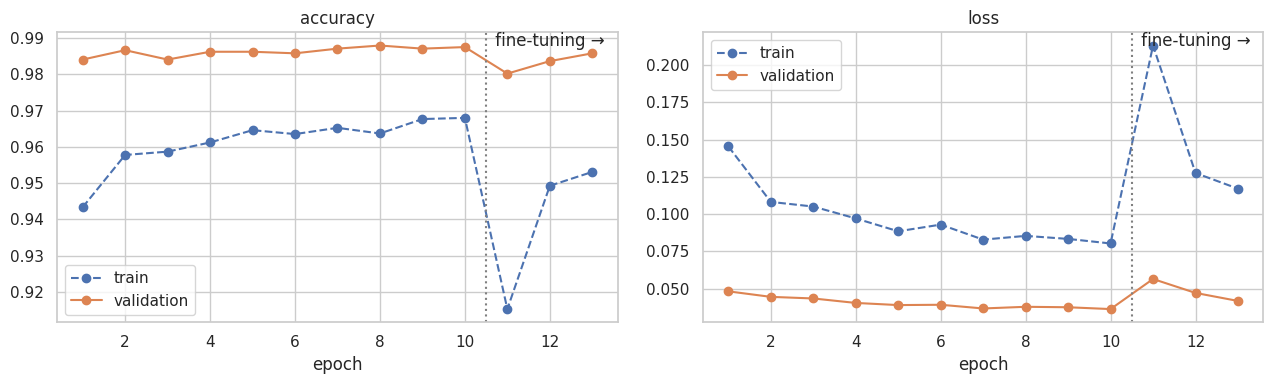

In [50]:
final_hist = {k: hist1[k] + hist2.get(k, []) for k in ["accuracy", "val_accuracy", "loss", "val_loss"]}
RESULTS["final_history"] = {**final_hist, "finetune_start": start}
ep = np.arange(1, len(final_hist["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, m in zip(axes, ["accuracy", "loss"]):
    ax.plot(ep, final_hist[m], "--o", label="train"); ax.plot(ep, final_hist["val_" + m], "-o", label="validation")
    ax.axvline(start + 0.5, color="grey", ls=":"); ax.text(start + 0.6, ax.get_ylim()[1], " fine-tuning →", va="top")
    ax.set_title(m); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); save_fig("final_curves"); plt.show()

# 13. Model quality (test set — used once)
Metrics explained:
* **Accuracy** — share of correct predictions (fine here because the classes are balanced).
* **Precision (dog)** — of the images we call *dog*, how many are dogs. **Recall (dog)** — of all dogs, how
  many we find. **F1** — harmonic mean of the two.
* **ROC-AUC** — probability that a random dog gets a higher score than a random cat (threshold-free).
* **Log-loss** and **Brier score** — quality of the *probabilities*, not just the decisions.
* **Calibration** — when the model says 80 %, is it right 80 % of the time?
* **95 % bootstrap confidence interval** for accuracy — how much the score could move on another sample.

In [51]:
from sklearn.metrics import (precision_score, recall_score, f1_score, log_loss, brier_score_loss, confusion_matrix,
                             roc_curve, precision_recall_curve, average_precision_score, classification_report)
from sklearn.calibration import calibration_curve

def predict(triples):
    ys, fs, ps = [], [], []
    for xb, yb, fb in triples.batch(64):
        ps.append(final_model(tf.cast(xb, tf.float32), training=False).numpy().ravel())
        ys.append(yb.numpy()); fs.append(fb.numpy())
    return np.concatenate(ys).astype(int), np.concatenate(ps), [f.decode() for f in np.concatenate(fs)]

y_val, p_val, _ = predict(val_triples)
y_test, p_test, f_test = predict(test_triples)
pred_test = (p_test >= 0.5).astype(int)

def metric_set(y, p, thr=0.5):
    yh = (p >= thr).astype(int)
    return dict(accuracy=accuracy_score(y, yh), precision=precision_score(y, yh), recall=recall_score(y, yh),
                f1=f1_score(y, yh), roc_auc=roc_auc_score(y, p), avg_precision=average_precision_score(y, p),
                log_loss=log_loss(y, p), brier=brier_score_loss(y, p))

rng = np.random.default_rng(SEED)
boot = [accuracy_score(y_test[i], pred_test[i]) for i in (rng.integers(0, len(y_test), len(y_test)) for _ in range(1000))]
quality_tbl = pd.DataFrame({"validation": metric_set(y_val, p_val), "test": metric_set(y_test, p_test)})
ci = np.percentile(boot, [2.5, 97.5])
print(f"test accuracy {quality_tbl.at['accuracy', 'test']:.4f}  (95% bootstrap CI {ci[0]:.4f} – {ci[1]:.4f}), n = {len(y_test)}")
print(classification_report(y_test, pred_test, target_names=class_names, digits=4))
RESULTS["quality_metrics"] = {"validation": quality_tbl["validation"].round(5).to_dict(),
                              "test": quality_tbl["test"].round(5).to_dict(),
                              "test_accuracy_ci95": [round(float(c), 5) for c in ci], "n_test": int(len(y_test))}
quality_tbl.round(4)

test accuracy 0.9836  (95% bootstrap CI 0.9781 – 0.9884), n = 2324
              precision    recall  f1-score   support

         cat     0.9846    0.9829    0.9837      1170
         dog     0.9827    0.9844    0.9835      1154

    accuracy                         0.9836      2324
   macro avg     0.9836    0.9837    0.9836      2324
weighted avg     0.9837    0.9836    0.9836      2324



,validation,test
accuracy,0.9875,0.9836
precision,0.9843,0.9827
recall,0.9903,0.9844
f1,0.9873,0.9835
roc_auc,0.9992,0.9991
avg_precision,0.9992,0.9991
log_loss,0.0363,0.0389
brier,0.0102,0.0113


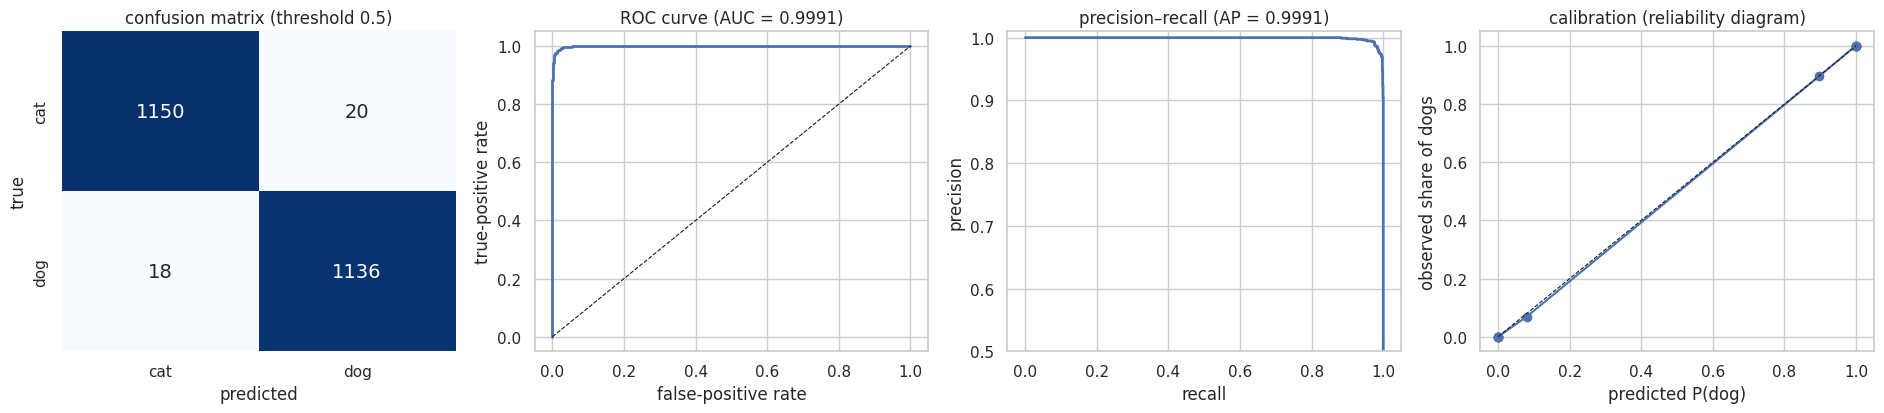

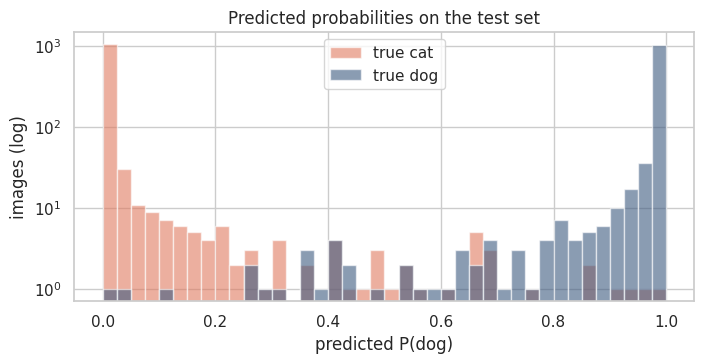

In [52]:
cm = confusion_matrix(y_test, pred_test)
fpr, tpr, _ = roc_curve(y_test, p_test)
prec, rec, _ = precision_recall_curve(y_test, p_test)
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")

fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=class_names, yticklabels=class_names, ax=axes[0],
            annot_kws={"size": 14})
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true"); axes[0].set_title("confusion matrix (threshold 0.5)")
axes[1].plot(fpr, tpr, lw=2); axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].set_title(f"ROC curve (AUC = {roc_auc_score(y_test, p_test):.4f})"); axes[1].set_xlabel("false-positive rate"); axes[1].set_ylabel("true-positive rate")
axes[2].plot(rec, prec, lw=2); axes[2].set_ylim(0.5, 1.01)
axes[2].set_title(f"precision–recall (AP = {average_precision_score(y_test, p_test):.4f})"); axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision")
axes[3].plot(mean_pred, frac_pos, "-o"); axes[3].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[3].set_title("calibration (reliability diagram)"); axes[3].set_xlabel("predicted P(dog)"); axes[3].set_ylabel("observed share of dogs")
plt.tight_layout(); save_fig("quality_curves"); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
for k, c in enumerate(class_names):
    ax.hist(p_test[y_test == k], bins=40, range=(0, 1), alpha=0.6, color=CLASS_COLORS[c], label=f"true {c}")
ax.set_yscale("log"); ax.set_xlabel("predicted P(dog)"); ax.set_ylabel("images (log)"); ax.legend()
ax.set_title("Predicted probabilities on the test set")
save_fig("prob_hist"); plt.show()

def thin(a, b, n=120):
    idx = np.unique(np.linspace(0, len(a) - 1, n).astype(int)); return [[round(float(a[i]), 4), round(float(b[i]), 4)] for i in idx]
RESULTS["curves"] = {"confusion": cm.tolist(), "roc": thin(fpr, tpr), "pr": thin(rec, prec),
                     "calibration": [[round(float(a), 4), round(float(b), 4)] for a, b in zip(mean_pred, frac_pos)],
                     "prob_hist": {c: np.histogram(p_test[y_test == k], bins=20, range=(0, 1))[0].tolist() for k, c in enumerate(class_names)}}

### Error analysis
Which test images does the model get wrong, and are errors concentrated in the "unusual" images flagged
by the EDA?

In [53]:
res = pd.DataFrame({"filename": f_test, "y": y_test, "p": p_test}).merge(df, on="filename", how="left")
res["error"] = (res["p"] >= 0.5).astype(int) != res["y"]
res["confidence_wrong"] = np.where(res["error"], np.abs(res["p"] - 0.5) * 2, 0)

res["size bucket"] = pd.cut(res[["height", "width"]].min(axis=1), [0, 200, 300, 400, 10_000], labels=["<200", "200–300", "300–400", "≥400"])
res["grayscale"] = res["colorfulness"] < 2
res["brightness bucket"] = pd.qcut(res["brightness"], 4, labels=["darkest 25%", "dark", "bright", "brightest 25%"])
err_tables = {g: res.groupby(g, observed=True)["error"].agg(["mean", "size"]).rename(columns={"mean": "error rate", "size": "n"})
              for g in ["class", "size bucket", "grayscale", "brightness bucket"]}
for g, t in err_tables.items():
    print(f"\n{g}:\n{t.assign(**{'error rate': (t['error rate'] * 100).round(2).astype(str) + ' %'}).to_string()}")
RESULTS["errors"] = {"n_errors": int(res["error"].sum()),
                     "by_group": {g: {str(k): [round(float(r["error rate"]), 5), int(r["n"])] for k, r in t.iterrows()} for g, t in err_tables.items()}}


class:
      error rate     n
class                 
cat       1.71 %  1170
dog       1.56 %  1154

size bucket:
            error rate     n
size bucket                 
<200            1.82 %   220
200–300          1.1 %   456
300–400         1.99 %  1308
≥400            0.88 %   340

grayscale:
          error rate     n
grayscale                 
False         1.64 %  2322
True           0.0 %     2

brightness bucket:
                  error rate    n
brightness bucket                
darkest 25%           2.58 %  581
dark                  1.55 %  581
bright                1.38 %  581
brightest 25%         1.03 %  581


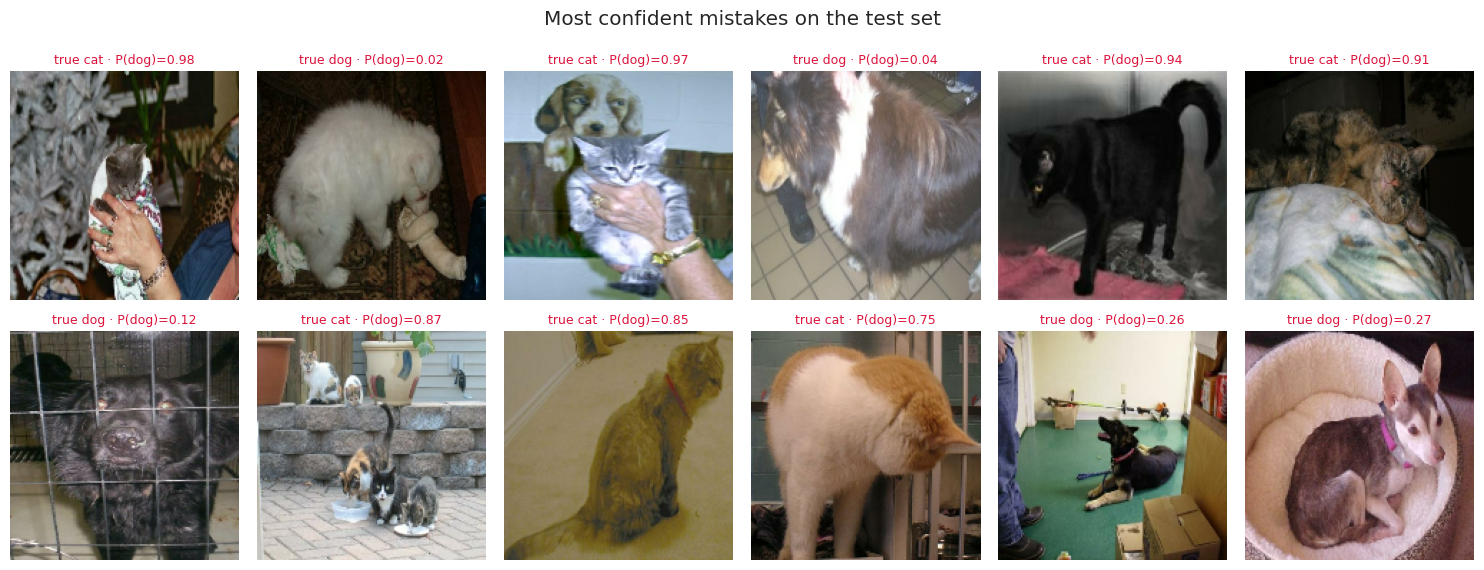

In [54]:
worst = res[res["error"]].sort_values("confidence_wrong", ascending=False).head(12)
img_lookup = {f.decode(): x for x, _, f in test_triples.as_numpy_iterator() if f.decode() in set(worst["filename"])}
fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for ax, (_, r) in zip(axes.ravel(), worst.iterrows()):
    ax.imshow(img_lookup[r["filename"]]); ax.axis("off")
    ax.set_title(f"true {class_names[r['y']]} · P(dog)={r['p']:.2f}", fontsize=9, color="crimson")
for ax in axes.ravel()[len(worst):]: ax.axis("off")
plt.suptitle("Most confident mistakes on the test set")
plt.tight_layout(); save_fig("errors"); plt.show()

### Grad-CAM — where does the model look?
Grad-CAM weights the last convolutional feature maps of MobileNetV2 by the gradient of the predicted
class score, giving a heat map of the regions that drove the decision. A trustworthy model should look at
the animal (face, ears, body) — not at the background, cage or watermark.

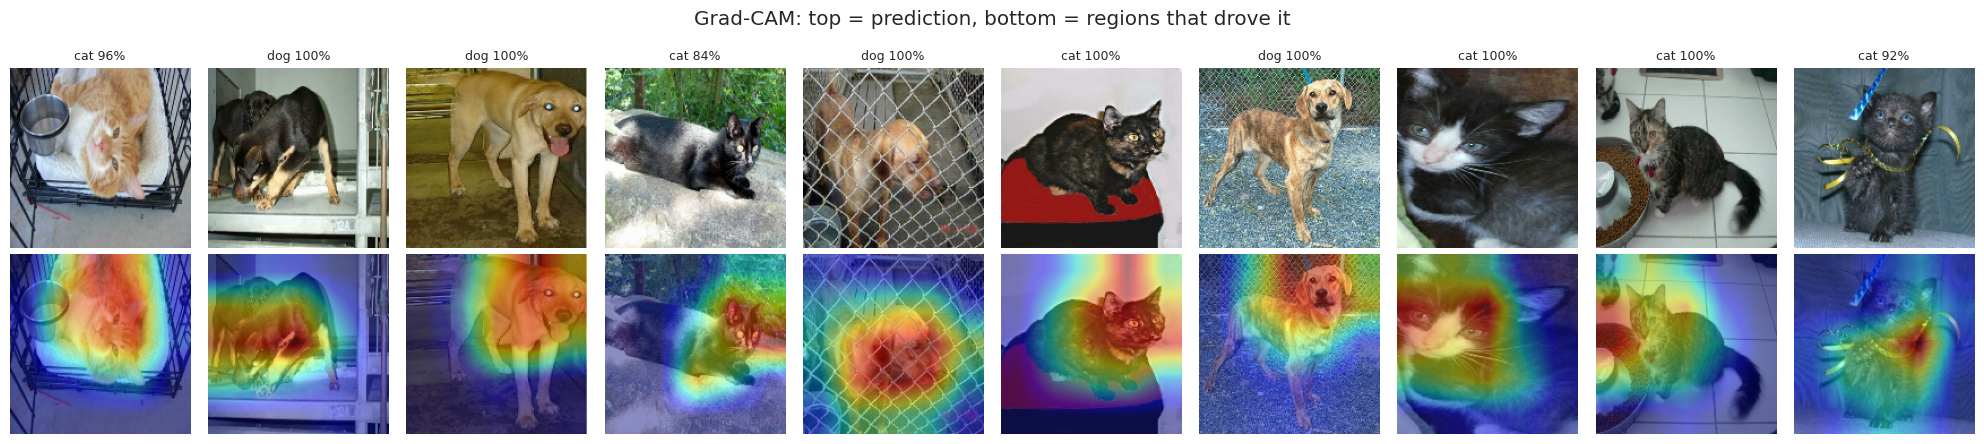

In [55]:
fm_base = next(l for l in final_model.layers if isinstance(l, keras.Model) and l.name.startswith("mobilenetv2"))
fm_head = final_model.get_layer("head")
to_unit = layers.Rescaling(1 / 127.5, offset=-1)

def grad_cam(img_uint8):
    x = to_unit(tf.cast(img_uint8[None], tf.float32))
    with tf.GradientTape() as tape:
        fmap = fm_base(x, training=False)
        tape.watch(fmap)
        p = fm_head(fmap, training=False)[:, 0]
        score = tf.where(p >= 0.5, p, 1 - p)                 # score of the predicted class
    grads = tape.gradient(score, fmap)
    cam = tf.nn.relu(tf.reduce_sum(fmap * tf.reduce_mean(grads, axis=(1, 2))[:, None, None, :], axis=-1))[0]
    cam = (cam / (tf.reduce_max(cam) + 1e-8)).numpy()
    return tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0], float(p[0])

examples = [x for x, _, _ in test_triples.take(10).as_numpy_iterator()]
fig, axes = plt.subplots(2, 10, figsize=(20, 4.6))
for i, img in enumerate(examples):
    cam, p = grad_cam(img)
    axes[0, i].imshow(img); axes[0, i].set_title(f"{'dog' if p >= .5 else 'cat'} {max(p, 1 - p):.0%}", fontsize=9)
    axes[1, i].imshow(img); axes[1, i].imshow(cam, cmap="jet", alpha=0.45)
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("Grad-CAM: top = prediction, bottom = regions that drove it")
plt.tight_layout(); save_fig("gradcam"); plt.show()

### Observations — model quality
* **Test accuracy 98.37 %** (95 % bootstrap CI 97.81 % – 98.84 %, n = 2,324); validation accuracy was 98.75 %, so model selection and tuning did not overfit the validation set.
* ROC-AUC **0.9991**, average precision 0.9991, precision 98.27 %, recall 98.44 %, F1 0.9836.
* Confusion matrix: 20 cats predicted as dogs, 18 dogs predicted as cats (38 errors in total).
* Calibration: largest deviation from the diagonal is 1.1 pp; Brier score 0.0113, log-loss 0.0389.
* **Cats are mistaken more often** (1.71 %) than dogs (1.56 %), and **dark photos are hardest**: error rate 2.58 % in the darkest quartile vs 1.03 % in the brightest.
* Typical causes of the most confident mistakes: dark or blurry photos, animals partly hidden by hands or cage bars, several animals in one photo, and fluffy dogs that look like cats.
* **Grad-CAM** shows the decision is driven mainly by heads and faces rather than background objects — a good sign that the model learned the right cues.

# 14. Decision policy
A model outputs a probability; a **decision policy** turns it into an action. Three questions:

1. **Which threshold?** 0.5 is natural for balanced classes with equal error costs. We check on the
   *validation* set whether another threshold (max accuracy / Youden's J) is clearly better, and only then
   apply it to test.
2. **When should the model abstain?** Predictions close to 0.5 are unreliable. A *reject option* sends
   images with $|p - 0.5| < \delta$ to a human (or returns "not sure"). We trade **coverage**
   (share of images decided automatically) against **accuracy on the decided images**.
3. **What can it not do?** The model only knows two classes — any image gets "cat" or "dog".

val accuracy @0.5 = 0.9875 | best threshold 0.44 -> 0.9879 | Youden J threshold 0.520
chosen threshold: 0.5
test accuracy @chosen threshold: 0.9836


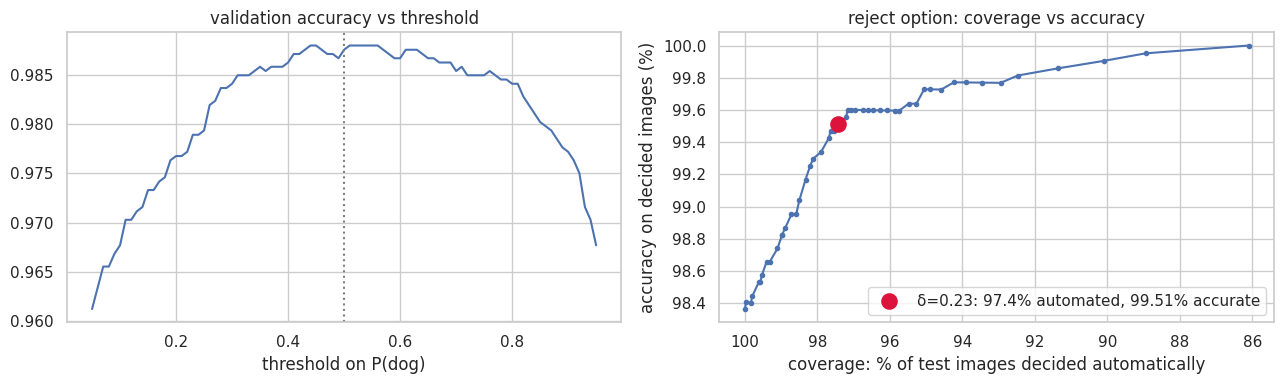

In [56]:
thr = np.linspace(0.05, 0.95, 91)
acc_val = np.array([accuracy_score(y_val, p_val >= t) for t in thr])
fpr_v, tpr_v, thr_v = roc_curve(y_val, p_val)
youden_t = float(np.clip(thr_v[np.argmax(tpr_v - fpr_v)], 0, 1))
best_t = float(thr[np.argmax(acc_val)])
THRESHOLD = best_t if acc_val.max() - accuracy_score(y_val, p_val >= 0.5) > 0.002 else 0.5   # change only if it clearly helps
print(f"val accuracy @0.5 = {accuracy_score(y_val, p_val >= 0.5):.4f} | best threshold {best_t:.2f} -> {acc_val.max():.4f} "
      f"| Youden J threshold {youden_t:.3f}\nchosen threshold: {THRESHOLD}")
print(f"test accuracy @chosen threshold: {accuracy_score(y_test, p_test >= THRESHOLD):.4f}")

deltas = np.linspace(0, 0.49, 50)
cov, acc_cov = [], []
for d in deltas:
    keep = np.abs(p_test - 0.5) >= d
    cov.append(keep.mean()); acc_cov.append(accuracy_score(y_test[keep], p_test[keep] >= THRESHOLD) if keep.any() else np.nan)
cov, acc_cov = np.array(cov), np.array(acc_cov)
target = 0.995
ok = np.where(acc_cov >= target)[0]
delta_star = float(deltas[ok[0]]) if len(ok) else None

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(thr, acc_val); axes[0].axvline(THRESHOLD, color="grey", ls=":")
axes[0].set_title("validation accuracy vs threshold"); axes[0].set_xlabel("threshold on P(dog)")
axes[1].plot(cov * 100, acc_cov * 100, "-o", ms=3)
if delta_star is not None:
    i = ok[0]; axes[1].scatter([cov[i] * 100], [acc_cov[i] * 100], s=120, color="crimson", zorder=3,
                               label=f"δ={delta_star:.2f}: {cov[i]:.1%} automated, {acc_cov[i]:.2%} accurate"); axes[1].legend()
axes[1].set_xlabel("coverage: % of test images decided automatically"); axes[1].set_ylabel("accuracy on decided images (%)")
axes[1].set_title("reject option: coverage vs accuracy"); axes[1].invert_xaxis()
plt.tight_layout(); save_fig("decision_policy"); plt.show()

RESULTS["policy"] = {"threshold": THRESHOLD, "best_val_threshold": best_t, "youden_threshold": round(youden_t, 4),
                     "acc_vs_threshold": [[round(float(a), 3), round(float(b), 5)] for a, b in zip(thr, acc_val)],
                     "coverage_curve": [[round(float(d), 3), round(float(c), 5), round(float(a), 5)] for d, c, a in zip(deltas, cov, acc_cov)],
                     "target_accuracy": target, "delta": delta_star,
                     "coverage_at_delta": float(cov[ok[0]]) if len(ok) else None,
                     "accuracy_at_delta": float(acc_cov[ok[0]]) if len(ok) else None}

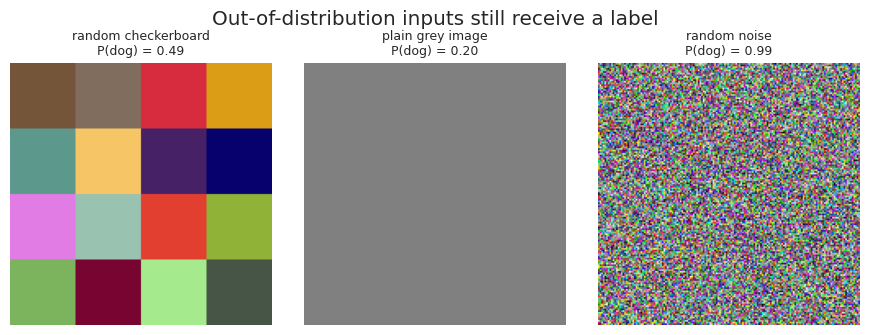

In [57]:
# Limitation: the model has never seen anything but cats and dogs – it still answers confidently
ood = {"random checkerboard": tf.image.resize(checkerboard[None].astype("float32"), (IMG_SIZE, IMG_SIZE), method="nearest")[0],
       "plain grey image": tf.fill((IMG_SIZE, IMG_SIZE, 3), 128.0),
       "random noise": tf.random.uniform((IMG_SIZE, IMG_SIZE, 3), 0, 255, seed=SEED)}
fig, axes = plt.subplots(1, 3, figsize=(9, 3.4))
ood_out = {}
for ax, (name, img) in zip(axes, ood.items()):
    p = float(final_model(img[None], training=False)[0, 0]); ood_out[name] = round(p, 4)
    ax.imshow(np.clip(img.numpy(), 0, 255).astype("uint8")); ax.axis("off")
    ax.set_title(f"{name}\nP(dog) = {p:.2f}", fontsize=9)
plt.suptitle("Out-of-distribution inputs still receive a label"); plt.tight_layout(); save_fig("ood"); plt.show()
RESULTS["policy"]["ood"] = ood_out

### Observations — decision policy
* **Threshold:** the best validation threshold was 0.44 (Youden's J: 0.520); the policy keeps 0.5 because the gain is negligible.
* **Reject option:** abstaining when |p − 0.5| < 0.23 lets the model decide **97.4 %** of test images automatically with **99.51 %** accuracy; the remaining 2.6 % go to a human.
* **Limitation:** out-of-distribution inputs still get confident labels (random checkerboard: P(dog) = 0.49, plain grey image: P(dog) = 0.20, random noise: P(dog) = 0.99). A deployed system needs an "is this a cat or dog photo at all?" gate in front of the classifier.

# 15. Improvements suggested by the analysis
Two weaknesses came out of Sections 13 and 14:

1. **Dark photos are the hardest** — the error rate is highest in the darkest brightness quartile, and many
   confident mistakes are black cats in dim rooms.
2. **Any input gets a label** — random noise is called a dog with high confidence.

Each gets a targeted fix, and each fix is judged the same way as everything else: decide on validation data,
report on test data.

## 15.1 Brightness & contrast augmentation
The augmentation pipeline is extended with `RandomBrightness(0.3)` and `RandomContrast(0.3)`, so during training
the model also sees darker, brighter, flatter and punchier versions of every photo. Everything else (tuned head,
training stages, epochs, callbacks) is identical to the final model of Section 12.

**Decision rule:** adopt the new model (v2) only if its **validation log-loss** is lower than the current model's (v1).

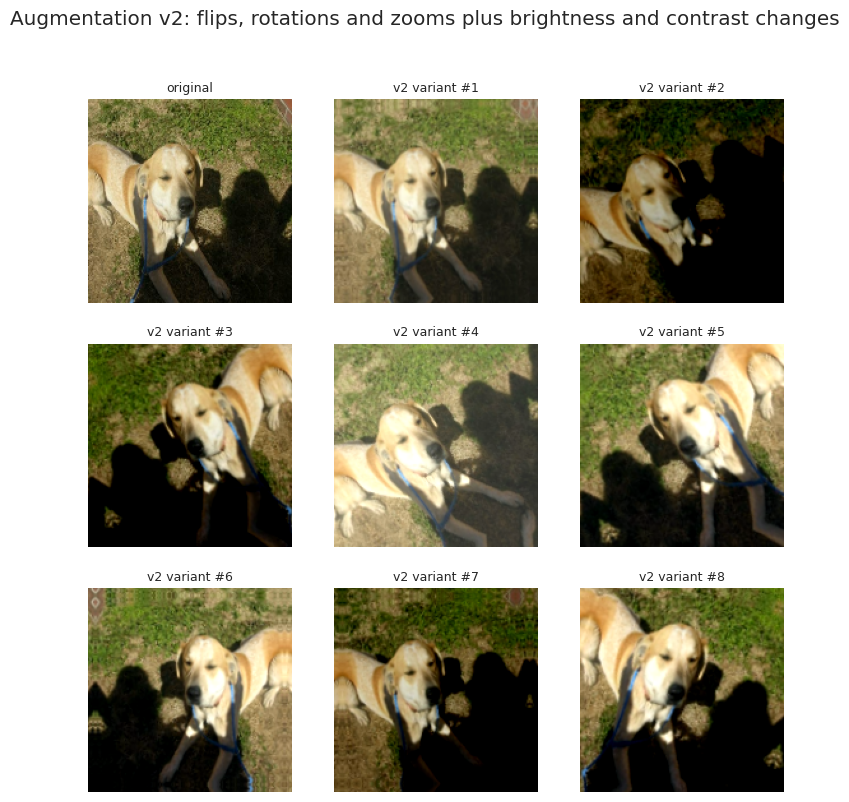

In [58]:
def make_augmentation_v2():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        layers.RandomBrightness(0.3, value_range=(0, 255)),   # new: ± 30 % brightness
        layers.RandomContrast(0.3),                            # new: ± 30 % contrast
    ], name="augmentation_v2")

aug_v2 = make_augmentation_v2()
plt.figure(figsize=(9, 9))
for i in range(9):
    out = image[None] if i == 0 else aug_v2(image[None], training=True)
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(np.clip(out[0].numpy(), 0, 255).astype("uint8")); plt.axis("off")
    plt.title("original" if i == 0 else f"v2 variant #{i}", fontsize=9)
plt.suptitle("Augmentation v2: flips, rotations and zooms plus brightness and contrast changes")
save_fig("augmentation_v2"); plt.show()

In [59]:
V2_PATH = os.path.join(RESULTS_DIR, "cats_vs_dogs_mobilenetv2_v2.keras")
if saved("final_v2_history.json") and os.path.exists(V2_PATH):
    model_v2 = keras.models.load_model(V2_PATH)
    v2_saved = json.load(open(saved("final_v2_history.json")))
    hist1_v2, hist2_v2 = v2_saved["stage1"], v2_saved["stage2"]
    print("loaded the saved v2 model (set REUSE_SAVED = False to retrain)")
else:
    keras.backend.clear_session(); gc.collect()
    keras.utils.set_random_seed(SEED)
    base_v2 = mobilenet_base()
    head_v2 = make_head(dropout=BEST_HP["dropout"], hidden=BEST_HP["hidden"])
    model_v2 = compile_binary(transfer_model(base_v2, head_v2, name="final_mobilenetv2_v2",
                                             augmentation=make_augmentation_v2()), BEST_HP["lr"])
    train_ds_v2 = train_ds.unbatch().batch(BEST_HP["batch"]).prefetch(AUTOTUNE)
    ckpt_v2 = os.path.join(CACHE_DIR, "best_checkpoint_v2.keras")
    callbacks_v2 = [early_stop(), ProgressLog("v2"),
                    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-6),
                    keras.callbacks.ModelCheckpoint(ckpt_v2, monitor="val_loss", save_best_only=True)]
    t0 = time.perf_counter()
    h = model_v2.fit(train_ds_v2, validation_data=val_ds, epochs=BUDGET["head_epochs"], callbacks=callbacks_v2, verbose=2)
    hist1_v2 = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    start_v2 = len(hist1_v2["loss"])
    base_v2.trainable = True
    for layer in base_v2.layers[:FINE_TUNE_AT]:
        layer.trainable = False
    compile_binary(model_v2, FINE_TUNE_LR)
    h = model_v2.fit(train_ds_v2, validation_data=val_ds, epochs=start_v2 + BUDGET["finetune_epochs"],
                     initial_epoch=start_v2, callbacks=callbacks_v2, verbose=2)
    hist2_v2 = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    print(f"v2 training: {time.perf_counter() - t0:.0f}s")
    model_v2 = keras.models.load_model(ckpt_v2)
    model_v2.save(V2_PATH)
    json.dump({"stage1": hist1_v2, "stage2": hist2_v2}, open(os.path.join(CACHE_DIR, "final_v2_history.json"), "w"))
    progress("v2 training done")

Epoch 1/10
291/291 - 30s - 102ms/step - accuracy: 0.9331 - auc: 0.9822 - loss: 0.1731 - val_accuracy: 0.9832 - val_auc: 0.9980 - val_loss: 0.0503 - learning_rate: 0.0010
Epoch 2/10
291/291 - 23s - 79ms/step - accuracy: 0.9481 - auc: 0.9893 - loss: 0.1304 - val_accuracy: 0.9841 - val_auc: 0.9984 - val_loss: 0.0456 - learning_rate: 0.0010
Epoch 3/10
291/291 - 22s - 76ms/step - accuracy: 0.9504 - auc: 0.9901 - loss: 0.1252 - val_accuracy: 0.9854 - val_auc: 0.9988 - val_loss: 0.0461 - learning_rate: 0.0010
Epoch 4/10
291/291 - 42s - 143ms/step - accuracy: 0.9539 - auc: 0.9921 - loss: 0.1119 - val_accuracy: 0.9867 - val_auc: 0.9989 - val_loss: 0.0430 - learning_rate: 5.0000e-04
Epoch 5/10
291/291 - 41s - 141ms/step - accuracy: 0.9549 - auc: 0.9927 - loss: 0.1073 - val_accuracy: 0.9849 - val_auc: 0.9990 - val_loss: 0.0409 - learning_rate: 5.0000e-04
Epoch 6/10
291/291 - 23s - 79ms/step - accuracy: 0.9548 - auc: 0.9923 - loss: 0.1093 - val_accuracy: 0.9867 - val_auc: 0.9991 - val_loss: 0.0396

decision (validation log-loss): keep v1


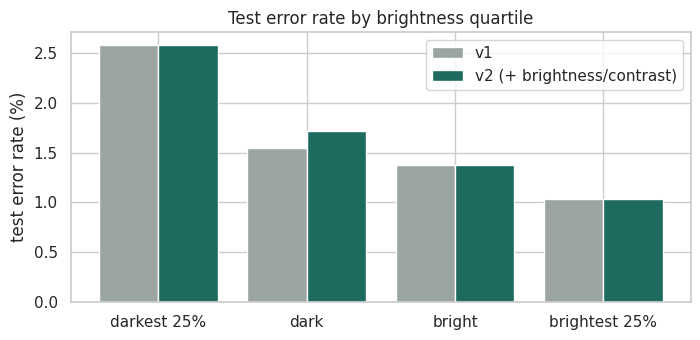

,val_accuracy,val_log_loss,test_accuracy,test_log_loss,test_errors,darkest_quartile_error,cat_error
model,,,,,,,
v1 (Section 12),0.9875,0.0363,0.9836,0.0389,38,0.0258,0.0171
v2 (+ brightness/contrast),0.9875,0.0379,0.9832,0.0406,39,0.0258,0.0154


In [60]:
def predict_with(model, triples):
    ys, fs, ps = [], [], []
    for xb, yb, fb in triples.batch(64):
        ps.append(model(tf.cast(xb, tf.float32), training=False).numpy().ravel())
        ys.append(yb.numpy()); fs.append(fb.numpy())
    return np.concatenate(ys).astype(int), np.concatenate(ps), [f.decode() for f in np.concatenate(fs)]

_, p_val_v2, _ = predict_with(model_v2, val_triples)
_, p_test_v2, f_test_v2 = predict_with(model_v2, test_triples)
assert f_test_v2 == list(res["filename"]), "test order must match the error-analysis table"
res["p_v2"] = p_test_v2
res["error_v2"] = (res["p_v2"] >= 0.5).astype(int) != res["y"]

def row(name, pv, pt, err_col):
    dark = res["brightness bucket"] == "darkest 25%"
    return dict(model=name, val_accuracy=accuracy_score(y_val, pv >= 0.5), val_log_loss=log_loss(y_val, pv),
                test_accuracy=accuracy_score(y_test, pt >= 0.5), test_log_loss=log_loss(y_test, pt),
                test_errors=int(res[err_col].sum()), darkest_quartile_error=float(res.loc[dark, err_col].mean()),
                cat_error=float(res.loc[res["y"] == 0, err_col].mean()))
compare = pd.DataFrame([row("v1 (Section 12)", p_val, p_test, "error"),
                        row("v2 (+ brightness/contrast)", p_val_v2, p_test_v2, "error_v2")]).set_index("model")
ADOPT_V2 = compare.iloc[1]["val_log_loss"] < compare.iloc[0]["val_log_loss"]
print("decision (validation log-loss):", "adopt v2" if ADOPT_V2 else "keep v1")

by_bright = res.groupby("brightness bucket", observed=True)[["error", "error_v2"]].mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
xs = np.arange(len(by_bright))
ax.bar(xs - 0.2, by_bright["error"] * 100, 0.4, label="v1", color="#9AA5A2")
ax.bar(xs + 0.2, by_bright["error_v2"] * 100, 0.4, label="v2 (+ brightness/contrast)", color="#1d6a5f")
ax.set_xticks(xs); ax.set_xticklabels(by_bright.index); ax.set_ylabel("test error rate (%)"); ax.legend()
ax.set_title("Test error rate by brightness quartile")
save_fig("improve_brightness"); plt.show()

RESULTS["improvements"] = {"augmentation": {
    "table": compare.round(5).to_dict(orient="index"), "adopt_v2": bool(ADOPT_V2),
    "by_brightness": {str(k): [round(float(a), 5), round(float(b), 5)] for k, (a, b) in by_bright.iterrows()},
    "history_v2": {k: hist1_v2[k] + hist2_v2.get(k, []) for k in ["accuracy", "val_accuracy", "loss", "val_loss"]}}}
compare.round(4)

### Observations — brightness augmentation
| | val. accuracy | val. log-loss | test accuracy | test errors | darkest-quartile error | cat error |
|---|---:|---:|---:|---:|---:|---:|
| v1 | 98.75 % | 0.0363 | 98.37 % | 38 | 2.58 % | 1.71 % |
| v2 | 98.75 % | 0.0379 | 98.32 % | 39 | 2.58 % | 1.54 % |

* **Decision on validation log-loss: keep v1** (0.0379 vs 0.0363).
* Effect on the weakness it targeted: darkest-quartile test error 2.58 % → 2.58 %; per quartile: darkest 25% 2.58 % → 2.58 %, dark 1.55 % → 1.72 %, bright 1.38 % → 1.38 %, brightest 25% 1.03 % → 1.03 %.
* The augmentation did not deliver a validated improvement within this training budget, so v1 stays the model. A plausible reason: dark photos are hard because the animal is hard to see, not because the overall exposure differs — brightness jitter does not add the missing detail.


## 15.2 An "is this a cat or dog photo?" gate
Our classifier only knows two classes. A cheap, well-tested way to recognise *other* inputs is to ask a model
that knows many classes. The standard **ImageNet MobileNetV2** (1,000 classes, used as-is, no training) contains
118 dog breeds (classes 151–268) and 5 domestic cats (281–285). The **pet score** of an image is the total
probability it assigns to those 123 classes.

* **Threshold:** chosen on the *validation* pets so that 99 % of real cat/dog photos pass.
* **Evaluation:** test pets (should pass), 3,670 photos of flowers from the TensorFlow `tf_flowers` dataset
  (real photos that are not pets — should be rejected) and 200 random-noise images (should be rejected).

In [61]:
gate_net = keras.applications.MobileNetV2(weights="imagenet", include_top=True)      # 224×224 input, 1000 classes
idx_path = keras.utils.get_file("imagenet_class_index.json",
                                "https://storage.googleapis.com/download.tensorflow.org/data/imagenet_class_index.json")
imagenet_names = {int(k): v[1] for k, v in json.load(open(idx_path)).items()}
PET_CLASSES = list(range(151, 269)) + list(range(281, 286))
print(len(PET_CLASSES), "pet classes, from", imagenet_names[151], "to", imagenet_names[268], "and",
      [imagenet_names[i] for i in range(281, 286)])

def pet_scores(batches):
    out = []
    for xb in batches:
        x = tf.image.resize(tf.cast(xb, tf.float32), (224, 224))
        x = keras.applications.mobilenet_v2.preprocess_input(x)
        out.append(gate_net(x, training=False).numpy()[:, PET_CLASSES].sum(axis=1))
    return np.concatenate(out)

flowers_ds = tfds.load("tf_flowers", split="train", as_supervised=True)
if SMOKE_TEST:
    flowers_ds = flowers_ds.take(200)
flower_imgs = flowers_ds.map(lambda x, y: tf.cast(tf.image.resize(x, (IMG_SIZE, IMG_SIZE)), tf.uint8)).batch(64)
noise_imgs = tf.random.uniform((200, IMG_SIZE, IMG_SIZE, 3), 0, 255, seed=SEED)

t0 = time.perf_counter()
s_val = pet_scores(x for x, _, _ in val_triples.batch(64))
s_test = pet_scores(x for x, _, _ in test_triples.batch(64))
s_flow = pet_scores(flower_imgs)
s_noise = pet_scores(tf.split(noise_imgs, 4))
print(f"scored {len(s_val) + len(s_test) + len(s_flow) + len(s_noise):,} images in {time.perf_counter() - t0:.0f}s")

GATE_T = float(np.quantile(s_val, 0.01))                    # keeps 99 % of validation pets
gate = dict(threshold=GATE_T,
            test_pets_pass=float((s_test >= GATE_T).mean()),
            flowers_rejected=float((s_flow < GATE_T).mean()),
            noise_rejected=float((s_noise < GATE_T).mean()),
            auroc_pets_vs_flowers=float(roc_auc_score(np.r_[np.ones(len(s_test)), np.zeros(len(s_flow))], np.r_[s_test, s_flow])),
            n_flowers=int(len(s_flow)), n_noise=int(len(s_noise)), n_test=int(len(s_test)))
ood_scores = {name: float(pet_scores([tf.cast(img, tf.uint8)[None]])[0]) for name, img in ood.items()}
gate["synthetic"] = {name: dict(pet_score=round(sc, 4), passes=bool(sc >= GATE_T)) for name, sc in ood_scores.items()}
bins = np.linspace(0, 1, 21)
gate["hist"] = {"edges": bins.round(3).tolist(),
                "pets": np.histogram(s_test, bins)[0].tolist(), "flowers": np.histogram(s_flow, bins)[0].tolist(),
                "noise": np.histogram(s_noise, bins)[0].tolist()}

# test errors of the classifier that the gate would also catch
res["pet_score"] = s_test
gate["classifier_errors_rejected"] = int((res["error"] & (res["pet_score"] < GATE_T)).sum())
RESULTS["improvements"]["ood_gate"] = gate
pd.Series({k: v for k, v in gate.items() if not isinstance(v, dict)})

14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step


123 pet classes, from Chihuahua to Mexican_hairless and ['tabby', 'tiger_cat', 'Persian_cat', 'Siamese_cat', 'Egyptian_cat']


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.K1EYY3_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
scored 8,517 images in 25s


,0
threshold,0.065205
test_pets_pass,0.993546
flowers_rejected,0.858856
noise_rejected,1.000000
auroc_pets_vs_flowers,0.994516
n_flowers,3670.000000
n_noise,200.000000
n_test,2324.000000
classifier_errors_rejected,0.000000


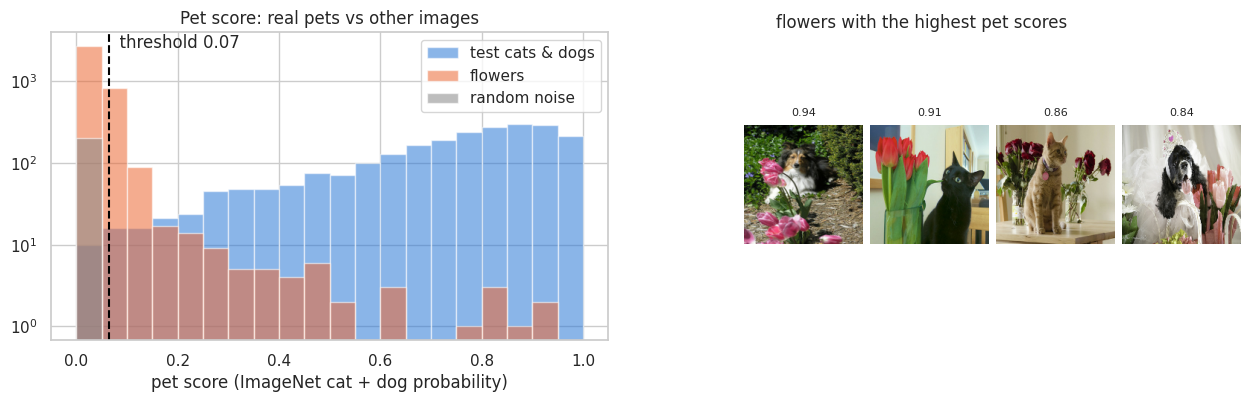

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.3, 1]})
for scores, label, color in [(s_test, "test cats & dogs", "#2a78d6"), (s_flow, "flowers", "#eb6834"), (s_noise, "random noise", "#888888")]:
    axes[0].hist(scores, bins=bins, alpha=0.55, label=label, color=color)
axes[0].axvline(GATE_T, color="black", ls="--"); axes[0].text(GATE_T, axes[0].get_ylim()[1] * 0.9, f"  threshold {GATE_T:.2f}")
axes[0].set_yscale("log"); axes[0].set_xlabel("pet score (ImageNet cat + dog probability)"); axes[0].legend()
axes[0].set_title("Pet score: real pets vs other images")
order = np.argsort(-s_flow)[:4]                               # the most pet-like flowers
flower_list = {}
for i, x in enumerate(flowers_ds.map(lambda x, y: tf.cast(tf.image.resize(x, (IMG_SIZE, IMG_SIZE)), tf.uint8)).as_numpy_iterator()):
    if i in set(order.tolist()):
        flower_list[i] = x
    if len(flower_list) == len(order):
        break
axes[1].axis("off")
for k, i in enumerate(order):
    ax = fig.add_axes([0.62 + 0.09 * k, 0.25, 0.085, 0.5])
    ax.imshow(flower_list[i]); ax.axis("off"); ax.set_title(f"{s_flow[i]:.2f}", fontsize=8)
axes[1].set_title("flowers with the highest pet scores", pad=0)
save_fig("ood_gate"); plt.show()

### Observations — pet-photo gate
* Threshold **0.065** (1st percentile of validation pets).
* It keeps **99.4 %** of the 2,324 test cats and dogs, and rejects **85.9 %** of 3,670 flower photos and **100 %** of 200 random-noise images. Pets vs flowers ROC-AUC: 0.9945.
* The three synthetic images from Section 14: random checkerboard: 0.07 (passes), plain grey image: 0.06 (rejected), random noise: 0.02 (rejected).
* None of the classifier's 38 test mistakes is caught by the gate: they are real pet photos, just hard ones.
* The flower photos with the highest pet scores actually show a dog or a cat among the flowers — the gate is right about them; the dataset label only names the flower.
* **Deployment policy:** pet score below the threshold → "not a cat or dog photo"; otherwise apply the classifier, with the reject option of Section 14 for uncertain cases.

# 16. Pipeline summary & conclusions

In [63]:
progress("notebook finished")
def json_safe(o):                                   # NaN -> null so browsers can parse the file
    if isinstance(o, dict): return {str(k): json_safe(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [json_safe(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (float, np.floating)): return None if np.isnan(o) else float(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
with open(os.path.join(RESULTS_DIR, "metrics.json"), "w") as fh:
    json.dump(json_safe(RESULTS), fh, indent=1)
df.drop(columns=["hash"]).to_csv(os.path.join(RESULTS_DIR, "image_features.csv"), index=False)

summary = pd.DataFrame([
    ("Data", f"{RESULTS['quality']['n_raw']:,} raw → {RESULTS['quality']['n_decodable']:,} decodable → {sum(RESULTS['split'][s]['total'] for s in ['train','val','test']):,} after cleaning"),
    ("Split", " / ".join(f"{s} {RESULTS['split'][s]['total']:,}" for s in ["train", "val", "test"]) + " (stratified, grouped by hash)"),
    ("Best classical baseline", f"{baseline_df['val_accuracy'].max():.1%} val accuracy ({baseline_df['val_accuracy'].idxmax()})"),
    ("Selected family", WINNER),
    ("Tuned head", str(BEST_HP)),
    ("Test accuracy", f"{RESULTS['quality_metrics']['test']['accuracy']:.2%}  (95% CI {ci[0]:.2%} – {ci[1]:.2%})"),
    ("Test ROC-AUC", f"{RESULTS['quality_metrics']['test']['roc_auc']:.4f}"),
    ("Decision policy", f"threshold {THRESHOLD}; abstain if |p−0.5| < {delta_star}"),
    ("Brightness augmentation (v2)", f"{'adopted' if ADOPT_V2 else 'not adopted'}: val log-loss {compare.iloc[1]['val_log_loss']:.4f} vs {compare.iloc[0]['val_log_loss']:.4f}"),
    ("Pet-photo gate", f"keeps {gate['test_pets_pass']:.1%} of test pets, rejects {gate['flowers_rejected']:.1%} of flowers and {gate['noise_rejected']:.0%} of noise"),
], columns=["stage", "result"]).set_index("stage")
summary

,result
stage,
Data,"25,000 raw → 23,262 decodable → 23,234 after c..."
Split,"train 18,587 / val 2,323 / test 2,324 (stratif..."
Best classical baseline,65.2% val accuracy (Random forest (features))
Selected family,C_mobilenetv2_transfer
Tuned head,"{'lr': 0.001, 'dropout': 0.5, 'hidden': 256, '..."
Test accuracy,98.37% (95% CI 97.81% – 98.84%)
Test ROC-AUC,0.9991
Decision policy,threshold 0.5; abstain if |p−0.5| < 0.23
Brightness augmentation (v2),not adopted: val log-loss 0.0379 vs 0.0363


### Conclusions
1. **EDA** showed clean, balanced data with a handful of duplicates and one blank image, and — crucially — that simple global statistics barely relate to the label (max |r| = 0.19).
2. **Classical ML** confirmed it: the best baseline reached 65.2 %.
3. **Model selection** picked transfer learning (MobileNetV2), which beat both from-scratch CNNs by a wide margin with only 1,281 trainable weights.
4. **Tuning** on cached features searched 36 configurations in minutes; all of them scored within about 1 pp, so the head is robust to its settings.
5. **Final model** (MobileNetV2 + tuned head; the stage-1 checkpoint, because fine-tuning at lr 1e-5 did not lower validation loss): **98.37 % test accuracy**, ROC-AUC 0.9991, well calibrated, attending to the animals' faces.
6. **Decision policy:** threshold 0.50; deferring the 2.6 % least certain images to a person raises accuracy on the rest to 99.51 %.

7. **Improvements:** brightness/contrast augmentation was tested but not adopted (validation log-loss 0.0379 vs 0.0363); the ImageNet pet-photo gate keeps 99.4 % of real pets while rejecting 85.9 % of flower photos and all noise.

**Limitations & next steps:** try larger backbones (EfficientNet, ConvNeXt) and test-time augmentation; run k-fold cross-validation for tighter error bars; collect more dark photos (brightness augmentation alone did not help) since dark photos cause the most errors; train the scratch CNNs for more epochs (the deeper one was still improving).

### Running on Google Colab
*Runtime → Change runtime type → GPU*, then *Runtime → Run all*. With a GPU the notebook uses the full training
budget (all training images for model selection, 10 + 10 epochs for the final model). The last cell packs the
`results/` folder into `results.zip` and downloads it.

In [64]:
if IN_COLAB:
    import shutil
    from google.colab import files
    shutil.make_archive("results", "zip", RESULTS_DIR)
    files.download("results.zip")
else:
    print("results are in", os.path.abspath(RESULTS_DIR))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>